# Import

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostRegressor
from cuml.ensemble import RandomForestRegressor as cuRF
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder

/home/reesarosyid/Documents/Battery/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Config

In [2]:
DATA_PATH = "../Dataset/Dataset_Li.csv"
TARGET = "V_av"
UNIT = "V"
VAV_MIN, VAV_MAX = -13, 13  # V_av range kept for modelling

RANDOM_STATE = 42
TEST_SIZE = 0.2
K = 10
SHAP_SAMPLE = 3_000
PDP_TOP_N = 5
PDP_SAMPLE = 5_000
PDP_ICE_LINES = 200
AD_FIT_SAMPLE = 50_000
AD_KNN = 5
AD_PERCENTILE = 95
RF_TUNE_SAMPLE = 150_000    # random forest is tuned on a subsample

# same folds for baseline, grid search and tuned models
kf = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2",
}

ACCENT = "#4A7EBB"
GRID = "#D8DCE0"
TEXT = "#22262B"
SPINE = "#5C6370"
BASE_COLOR = "#B4442E"
TUNED_COLOR = ACCENT
DENSITY_CMAP = "Blues"

MAX_TITLE = 34
P_LOW, P_HIGH = 0.01, 0.99
TRIM_PRED_AXES = True


def style_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8, colors=SPINE, length=0)


def short_names(names):
    """'XGBoost (boosting)' -> 'XGBoost'"""
    return pd.Index(names).str.replace(r"\s*\(.*\)", "", regex=True)


def truncate(label):
    return label if len(label) <= MAX_TITLE else label[:MAX_TITLE - 3] + "..."


def trimmed_limits(values, pad_frac=0.05):
    low, high = np.quantile(values, [P_LOW, P_HIGH])
    pad = (high - low) * pad_frac
    return low - pad, high + pad


def feature_panels(data, plot_func, title, ncol=5):
    columns = data.select_dtypes("number").columns
    nrow = (len(columns) + ncol - 1) // ncol

    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
    axes = axes.ravel()

    for ax, column in zip(axes, columns):
        values = data[column].dropna()
        ax.set_title(truncate(column), fontsize=8.5, color=TEXT)
        plot_func(ax, values, values.min(), values.max())
        style_axes(ax)

    for ax in axes[len(columns):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=13, color=TEXT)
    fig.tight_layout()
    plt.show()


def draw_boxplot(ax, values, low, high):
    ax.boxplot(
        values,
        widths=0.55,
        showfliers=True,
        medianprops={"color": ACCENT, "linewidth": 2},
        boxprops={"color": SPINE},
        whiskerprops={"color": SPINE},
        capprops={"color": SPINE},
    )
    ax.set_xticks([])
    if low < high:
        pad = (high - low) * 0.12
        ax.set_ylim(low - pad, high + pad)


def draw_histogram(ax, values, low, high):
    if low == high:
        ax.text(0.5, 0.5, f"Constant\n{values.iloc[0]:.4g}",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([])
        ax.set_yticks([])
        return
    ax.hist(values.clip(low, high), bins=50, range=(low, high),
            color=ACCENT, edgecolor="white", linewidth=0.4)


def plot_correlation(data, method="spearman"):
    """Lower-triangular correlation heatmap. Returns the correlation matrix."""
    corr = data.select_dtypes(include="number").corr(method=method)
    n = len(corr)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(0.9 * n + 3, 0.9 * n + 1))
    heatmap = ax.imshow(np.ma.masked_where(mask, corr), cmap="coolwarm", vmin=-1, vmax=1)

    for i in range(n):
        for j in range(i + 1):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > 0.6 else TEXT)

    labels = [c.replace("MagpieData ", "") for c in corr.columns]
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.tick_params(colors=SPINE, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    bar = fig.colorbar(heatmap, ax=ax, shrink=0.6, ticks=[-1, -0.5, 0, 0.5, 1])
    bar.set_label(f"{method.title()} Correlation", fontsize=9, color=SPINE)
    bar.ax.tick_params(labelsize=8, colors=SPINE, length=0)
    bar.outline.set_visible(False)

    ax.set_title(f"{method.title()} Correlation Matrix", fontsize=13, color=TEXT, pad=14)
    fig.tight_layout()
    plt.show()
    return corr


def summarize_correlation(corr, target, threshold=0.8):
    target_corr = corr[target].drop(target).sort_values(key=np.abs, ascending=False)

    print(f"Correlation with '{target}':")
    for name, value in target_corr.items():
        print(f"  {value:+.3f}  {name}")

    features = corr.drop(index=target, columns=target).abs()
    upper = np.triu(np.ones(features.shape, dtype=bool), k=1)
    pairs = features.where(upper).stack().sort_values(ascending=False)
    pairs = pairs[pairs > threshold]

    print(f"\nFeature pairs with |correlation| > {threshold}:")
    if pairs.empty:
        print("  None")
    for (left, right), value in pairs.items():
        print(f"  {value:.3f}  {left} <-> {right}")

    return target_corr, pairs


def plot_target_correlation(corr, target):
    target_corr = corr[target].drop(target).dropna().sort_values(key=np.abs)
    labels = [c.replace("MagpieData ", "") for c in target_corr.index]
    colors = plt.cm.coolwarm((target_corr.to_numpy() + 1) / 2)

    fig, ax = plt.subplots(figsize=(8, 0.35 * len(target_corr) + 1.5))
    ax.barh(labels, target_corr, color=colors, height=0.7)
    ax.axvline(0, color=SPINE, linewidth=0.8)

    for y, value in enumerate(target_corr):
        ax.text(value + (0.01 if value >= 0 else -0.01), y, f"{value:+.2f}",
                ha="left" if value >= 0 else "right", va="center",
                fontsize=7.5, color=TEXT)

    ax.set_xlim(-1, 1)
    ax.set_xlabel("Correlation", fontsize=9, color=SPINE)
    style_axes(ax, grid_axis="x")
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"Feature correlation with {target}", fontsize=13, color=TEXT)
    fig.tight_layout()
    plt.show()


def cv_then_test(name, model, X_tr, y_tr, X_te, y_te, folds=kf):
    """K-fold CV on the training set, then refit on all of it and score the test set."""
    cv = cross_validate(model, X_tr, y_tr, cv=folds, scoring=SCORING,
                        n_jobs=1, error_score="raise")
    fold_rmse = -cv["test_RMSE"]
    fold_mae = -cv["test_MAE"]
    fold_r2 = cv["test_R2"]

    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    elapsed = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_te))

    row = {
        "model": name,
        "CV RMSE": fold_rmse.mean(), "CV RMSE std": fold_rmse.std(),
        "CV MAE": fold_mae.mean(), "CV MAE std": fold_mae.std(),
        "CV R2": fold_r2.mean(), "CV R2 std": fold_r2.std(),
        "test RMSE": mean_squared_error(y_te, y_pred) ** 0.5,
        "test MAE": mean_absolute_error(y_te, y_pred),
        "test R2": r2_score(y_te, y_pred),
        "CV (s)": cv["fit_time"].sum(), "refit (s)": elapsed,
    }
    print(f"{name:<24} CV MAE={row['CV MAE']:.4f}+/-{row['CV MAE std']:.4f}  "
          f"CV RMSE={row['CV RMSE']:.4f}  CV R2={row['CV R2']:.4f}  |  "
          f"test MAE={row['test MAE']:.4f}  ({row['CV (s)']:.0f}s)")
    return row, y_pred


def evaluate_all(named_models, X_tr, y_tr, X_te, y_te, heading):
    rows, preds = [], {}
    for name, model in named_models.items():
        row, preds[name] = cv_then_test(name, model, X_tr, y_tr, X_te, y_te)
        rows.append(row)

    table = pd.DataFrame(rows).set_index("model").sort_values("CV MAE")
    print(f"\n{heading}, {K}-fold CV (sorted by CV MAE)")
    print(table.round(4).to_string())
    return table, preds


def plot_pred_vs_actual(ax, y_true, y_pred, low, high):
    """Hexbin of predicted vs actual with the ideal and fitted lines.

    Metrics and the fitted line use all rows, regardless of the axis limits.
    """
    slope, intercept = np.polyfit(y_true, y_pred, 1)
    line = np.array([low, high])

    hexes = ax.hexbin(y_true, y_pred, gridsize=45, extent=(low, high, low, high),
                      bins="log", cmap=DENSITY_CMAP, mincnt=1)
    ideal, = ax.plot(line, line, color=TEXT, ls="--", lw=1.2,
                     label="perfect prediction (predicted = actual)")
    fitted, = ax.plot(line, slope * line + intercept, color=BASE_COLOR, lw=1.8,
                      label="fitted line")

    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal")
    style_axes(ax, grid_axis="both")

    metrics_text = (f"$R^2$ = {r2_score(y_true, y_pred):.2f}\n"
                    f"RMSE = {mean_squared_error(y_true, y_pred) ** 0.5:.2f} {UNIT}\n"
                    f"MAE = {mean_absolute_error(y_true, y_pred):.2f} {UNIT}")
    ax.text(0.04, 0.96, metrics_text, transform=ax.transAxes, va="top", ha="left",
            fontsize=10, color=TEXT,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
    return hexes, (ideal, fitted)

# Load Data

In [3]:
VAV_FEATURES = [
    "disch__MagpieData mean CovalentRadius",
    "charged_sg",
    "chg__MagpieData mean Electronegativity",
    "chg__MagpieData mean CovalentRadius",
    "ion_property_second",
    "discharged_sg",
    "chg__MagpieData range Electronegativity",
    "chg__MagpieData maximum Column",
    "chg__MagpieData maximum NpValence",
    "disch__MagpieData maximum Column",
    "chg__MagpieData minimum Electronegativity",
    "chg__MagpieData mean Column",
    "ion_property_first",
    "disch__MagpieData mean NValence",
    "charged_cs",
    "chg__frac s valence electrons",
    "disch__MagpieData maximum NpValence",
    "x1_charged",
    "chg__MagpieData mean MeltingT",
    "disch__MagpieData avg_dev CovalentRadius",
]

df = pd.read_csv(DATA_PATH)
df_vav = df[VAV_FEATURES + [TARGET]]
df_vav.head()

,disch__MagpieData mean CovalentRadius,charged_sg,chg__MagpieData mean Electronegativity,chg__MagpieData mean CovalentRadius,ion_property_second,discharged_sg,chg__MagpieData range Electronegativity,chg__MagpieData maximum Column,chg__MagpieData maximum NpValence,disch__MagpieData maximum Column,...,chg__MagpieData mean Column,ion_property_first,disch__MagpieData mean NValence,charged_cs,chg__frac s valence electrons,disch__MagpieData maximum NpValence,x1_charged,chg__MagpieData mean MeltingT,disch__MagpieData avg_dev CovalentRadius,V_av
0,100.833333,14.0,2.738000,95.400000,75.640097,14,2.62,16.0,4.0,16.0,...,12.6,5.391715,4.00,Monoclinic,0.391304,4.0,0.0,864.7860,43.111111,5.7810
1,121.333333,62.0,2.602500,118.000000,75.640097,139,2.23,17.0,5.0,17.0,...,13.0,5.391715,4.00,Orthorhombic,0.318182,5.0,0.0,221.4175,19.333333,3.4318
2,121.333333,223.0,2.602500,118.000000,75.640097,139,2.23,17.0,5.0,17.0,...,13.0,5.391715,4.00,Cubic,0.318182,5.0,0.0,221.4175,19.333333,3.9119
3,155.250000,139.0,1.103333,164.333333,75.640097,225,0.31,2.0,0.0,2.0,...,2.0,5.391715,1.75,Tetragonal,1.000000,0.0,0.0,1051.0000,20.750000,-0.0551
4,155.250000,12.0,1.103333,164.333333,75.640097,225,0.31,2.0,0.0,2.0,...,2.0,5.391715,1.75,Monoclinic,1.000000,0.0,0.0,1051.0000,20.750000,-0.0105


In [4]:
df_vav.describe().T

,count,mean,std,min,25%,50%,75%,max
disch__MagpieData mean CovalentRadius,850873.0,133.711172,1.638674e+01,46.117647,127.250000,133.600000,142.500000,200.500000
charged_sg,850200.0,116.649873,7.240715e+01,1.000000,58.000000,129.000000,187.000000,230.000000
chg__MagpieData mean Electronegativity,850873.0,1.642594,4.447608e-01,0.820000,1.364000,1.590000,1.806667,3.980000
chg__MagpieData mean CovalentRadius,850873.0,137.816598,2.306114e+01,31.000000,126.666667,137.166667,151.000000,220.000000
ion_property_second,850873.0,75.640097,2.842173e-14,75.640097,75.640097,75.640097,75.640097,75.640097
discharged_sg,850873.0,108.810113,7.466944e+01,1.000000,44.000000,119.000000,166.000000,230.000000
chg__MagpieData range Electronegativity,850873.0,0.958702,5.924552e-01,0.000000,0.560000,0.930000,1.230000,3.190000
chg__MagpieData maximum Column,850873.0,10.809587,4.539374e+00,1.000000,7.000000,12.000000,14.000000,17.000000
chg__MagpieData maximum NpValence,850873.0,1.240592,1.614896e+00,0.000000,0.000000,0.000000,2.000000,5.000000
disch__MagpieData maximum Column,850873.0,10.809587,4.539374e+00,1.000000,7.000000,12.000000,14.000000,17.000000


In [5]:
df_vav.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850873 entries, 0 to 850872
Data columns (total 21 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   disch__MagpieData mean CovalentRadius      850873 non-null  float64
 1   charged_sg                                 850200 non-null  float64
 2   chg__MagpieData mean Electronegativity     850873 non-null  float64
 3   chg__MagpieData mean CovalentRadius        850873 non-null  float64
 4   ion_property_second                        850873 non-null  float64
 5   discharged_sg                              850873 non-null  int64  
 6   chg__MagpieData range Electronegativity    850873 non-null  float64
 7   chg__MagpieData maximum Column             850873 non-null  float64
 8   chg__MagpieData maximum NpValence          850873 non-null  float64
 9   disch__MagpieData maximum Column           850873 non-null  float64
 10  chg__Mag

# EDA
## Missing Values and Duplicates

In [6]:
missing = df_vav.isna().sum()
missing = missing[missing > 0]

print("Missing values per column:")
print(missing.to_string() if not missing.empty else "  none")

Missing values per column:
charged_sg    673
charged_cs    673


In [7]:
# duplicates are checked on features only: identical inputs with different
# targets could end up in both train and test
feature_cols = df_vav.columns.drop(TARGET)

print(f"Duplicate rows (features only): {df_vav.duplicated(subset=feature_cols).sum():,}")

Duplicate rows (features only) = 1,876


In [8]:
df_vav = (
    df_vav
    .dropna()
    .drop_duplicates(subset=feature_cols, keep="first")
    .reset_index(drop=True)
)

print(f"rows remaining       : {len(df_vav):,}")
print(f"remaining NaN        : {int(df_vav.isna().sum().sum())}")
print(f"remaining duplicates : {int(df_vav.duplicated(subset=feature_cols).sum())}")

rows remaining       : 848,324
remaining NaN        : 0
remaining duplicates : 0


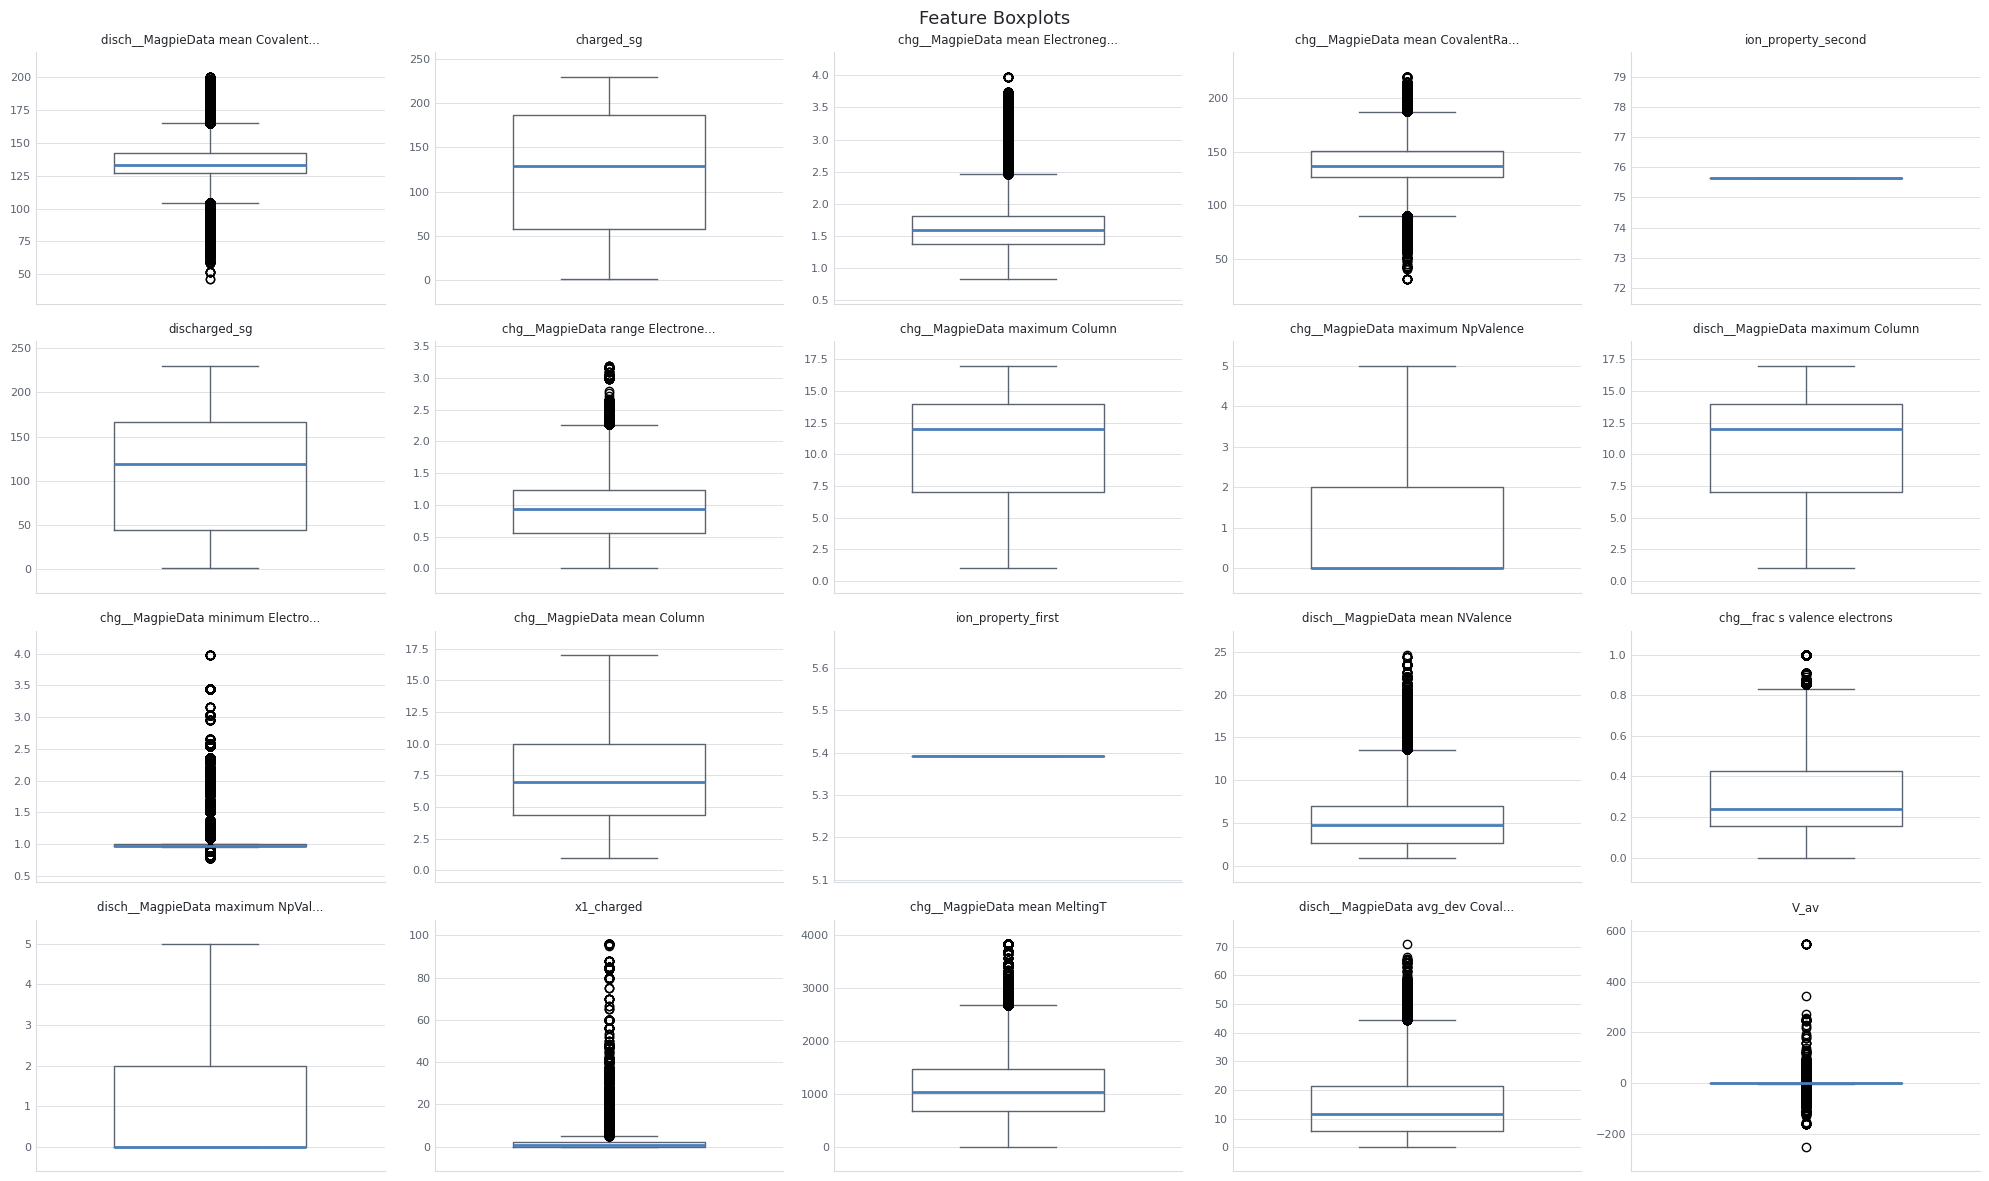

In [9]:
feature_panels(df_vav, draw_boxplot, "Feature Boxplots")

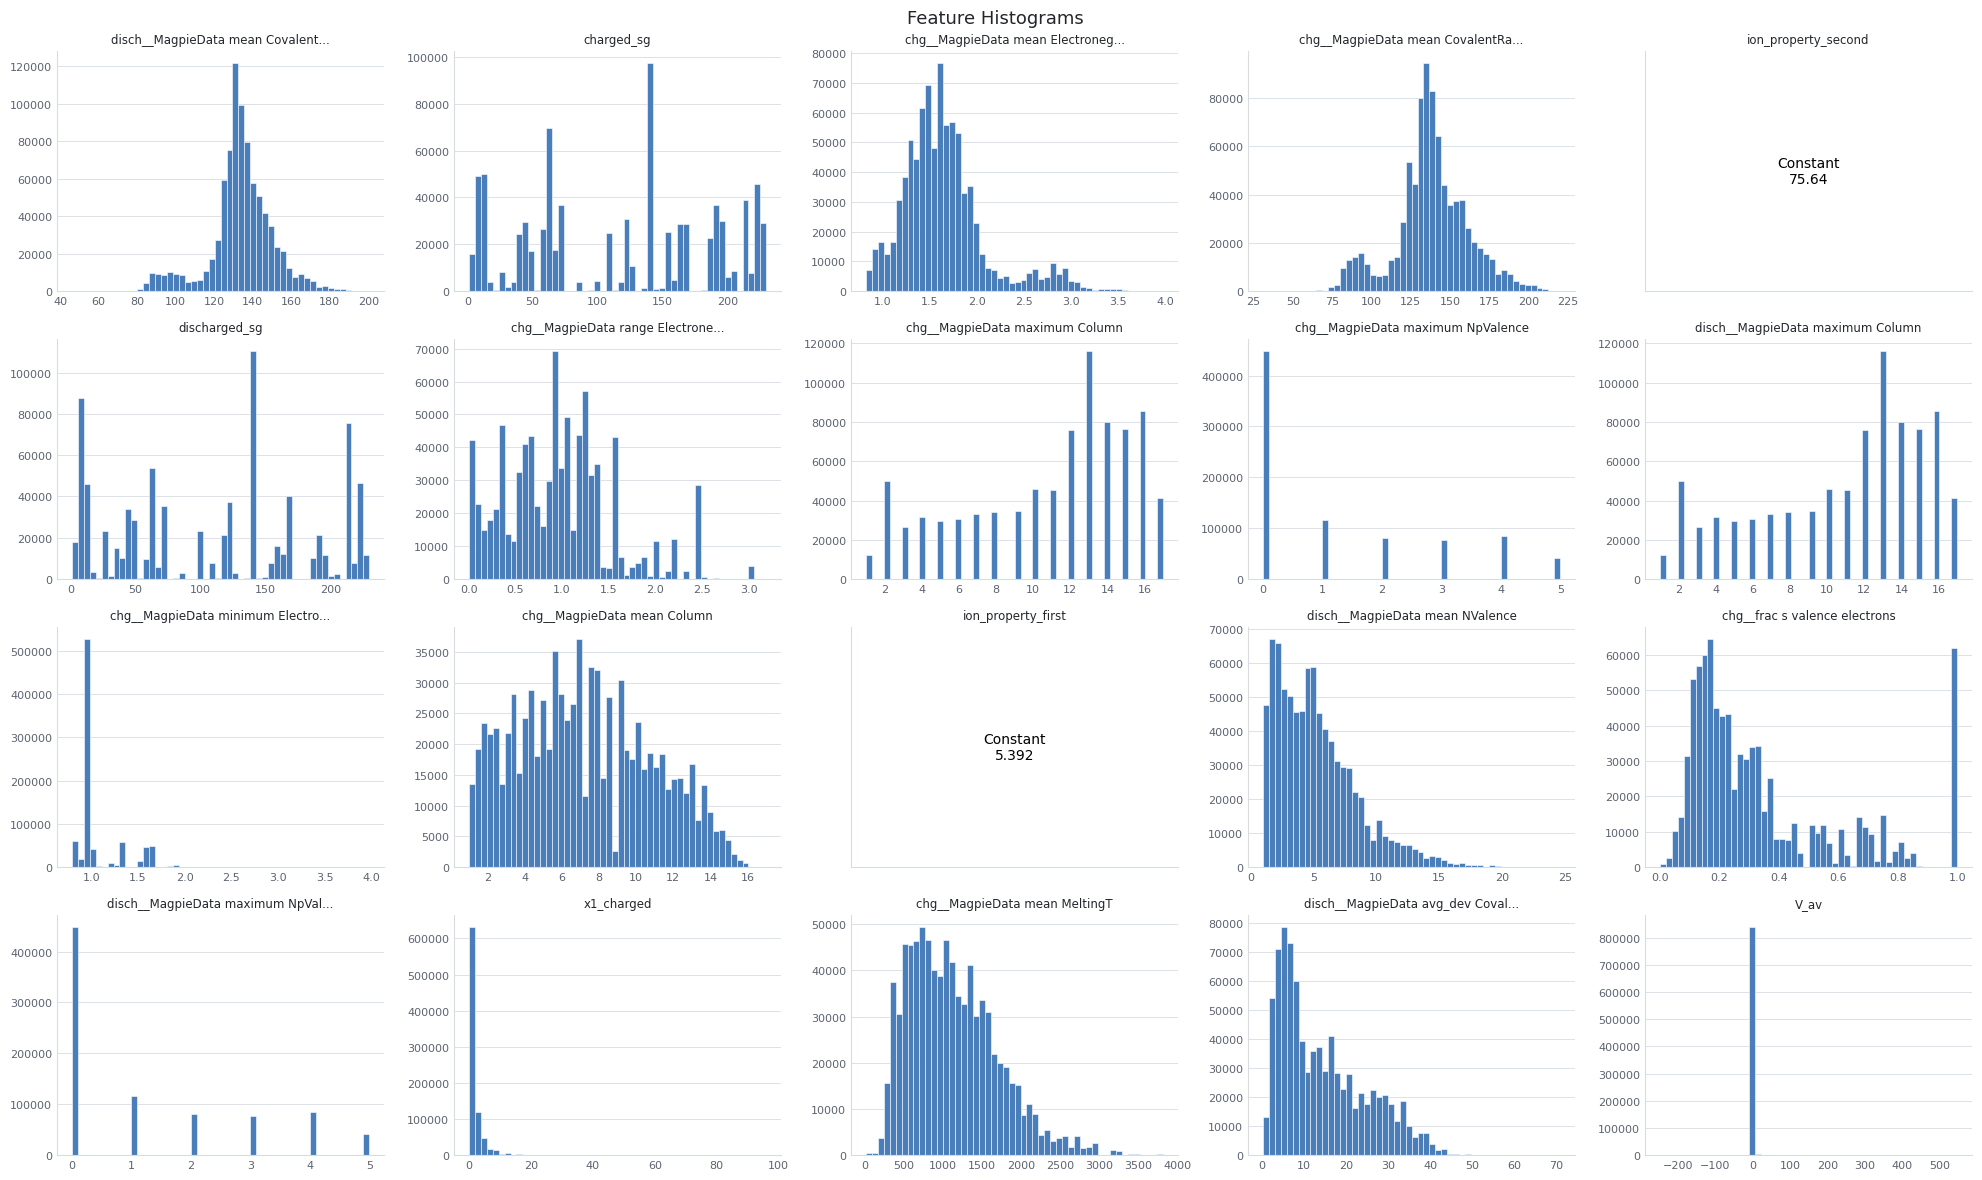

In [10]:
feature_panels(df_vav, draw_histogram, "Feature Histograms")

In [11]:
n_before = len(df_vav)
df_vav = df_vav[df_vav[TARGET].between(VAV_MIN, VAV_MAX)].reset_index(drop=True)

print(f"{TARGET} window      : [{VAV_MIN}, {VAV_MAX}] V")
print(f"rows dropped         : {n_before - len(df_vav):,} "
      f"({(n_before - len(df_vav)) / n_before:.2%})")
print(f"rows remaining       : {len(df_vav):,}")
print(f"{TARGET} range now   : {df_vav[TARGET].min():.3f} .. {df_vav[TARGET].max():.3f}")

V_av window      : [-13, 13] V
rows dropped         : 3,381 (0.40%)
rows remaining       : 844,943
V_av range now   : -12.983 .. 12.996


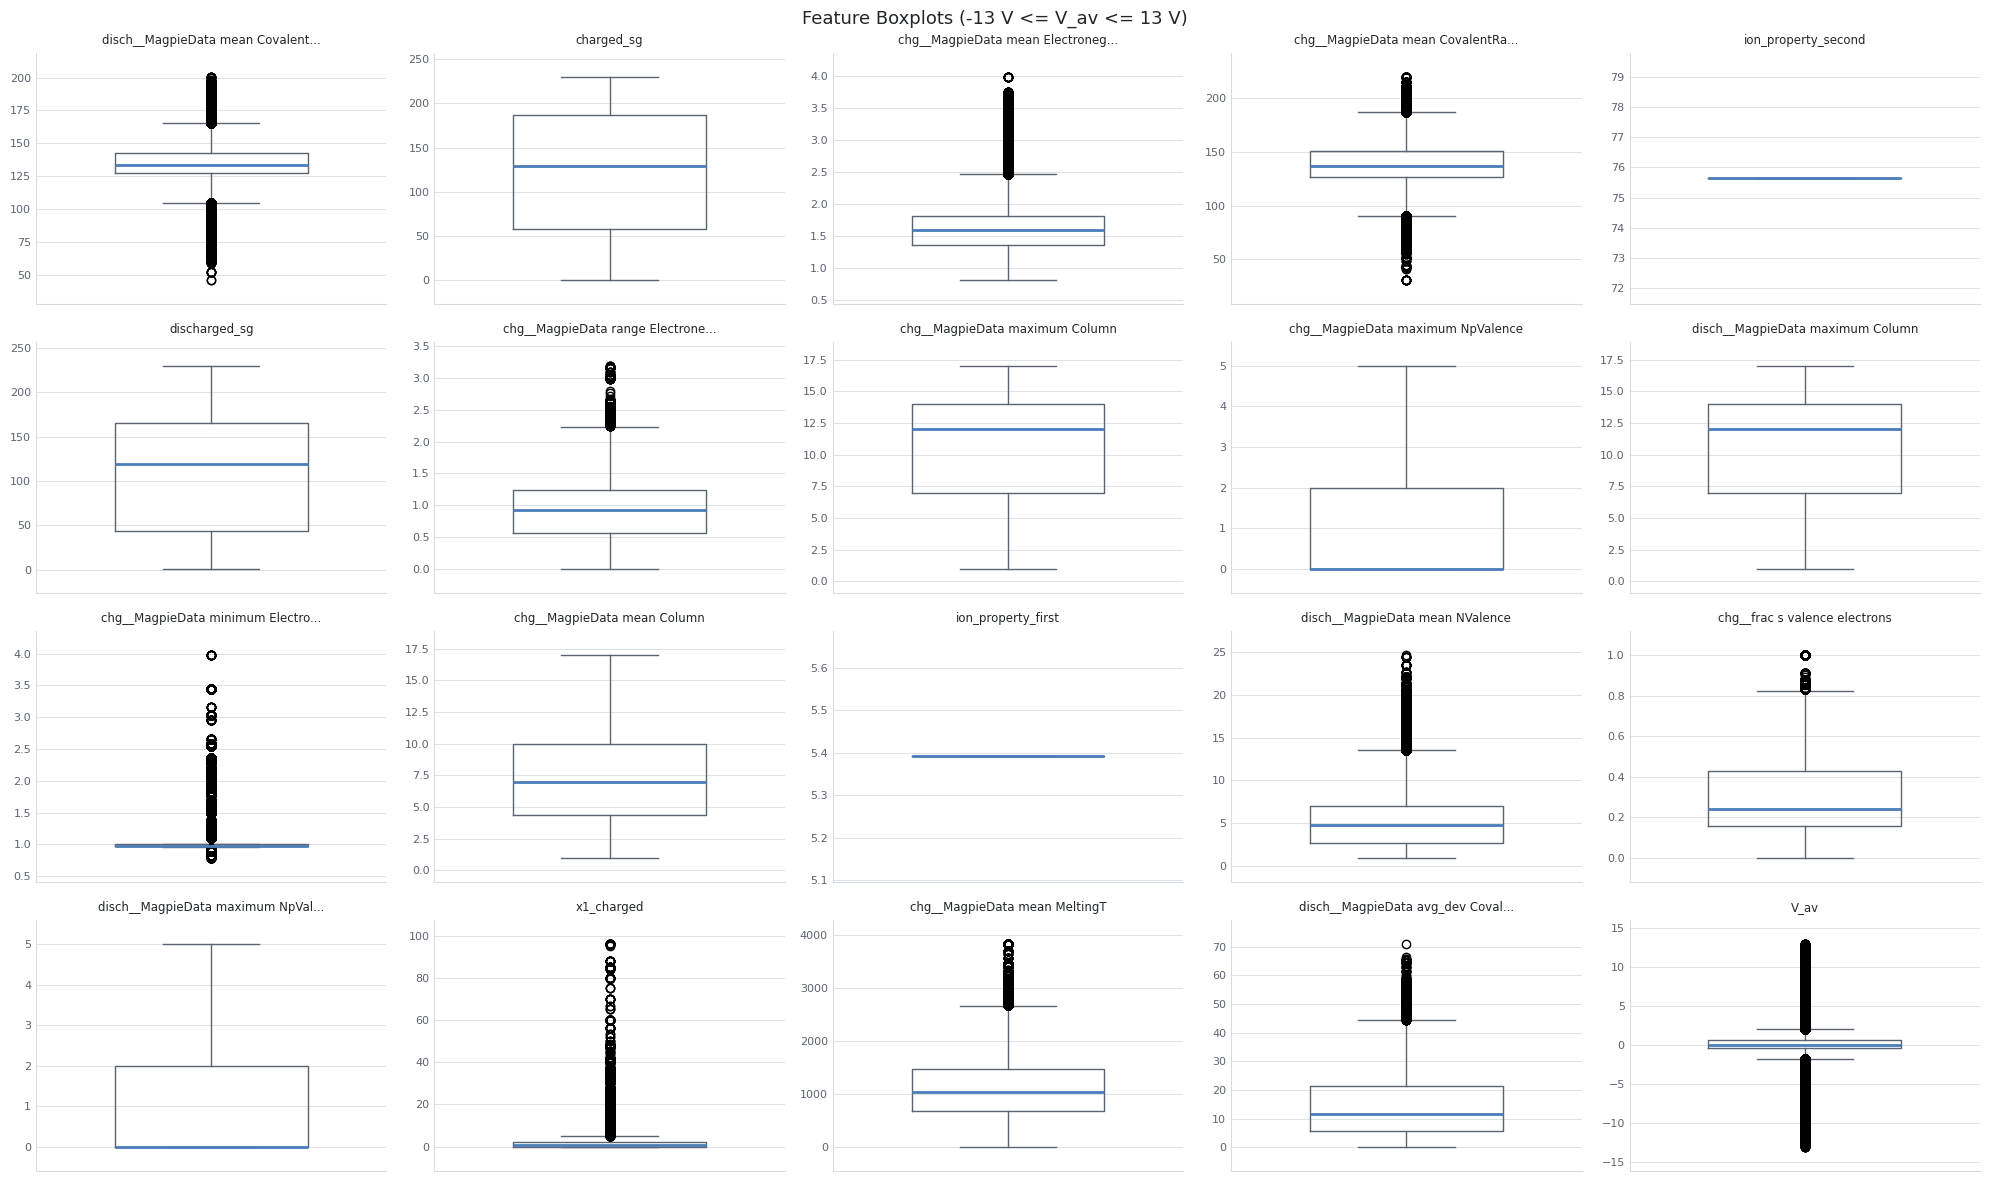

In [12]:
feature_panels(df_vav, draw_boxplot, f"Feature Boxplots ({VAV_MIN} V <= {TARGET} <= {VAV_MAX} V)")

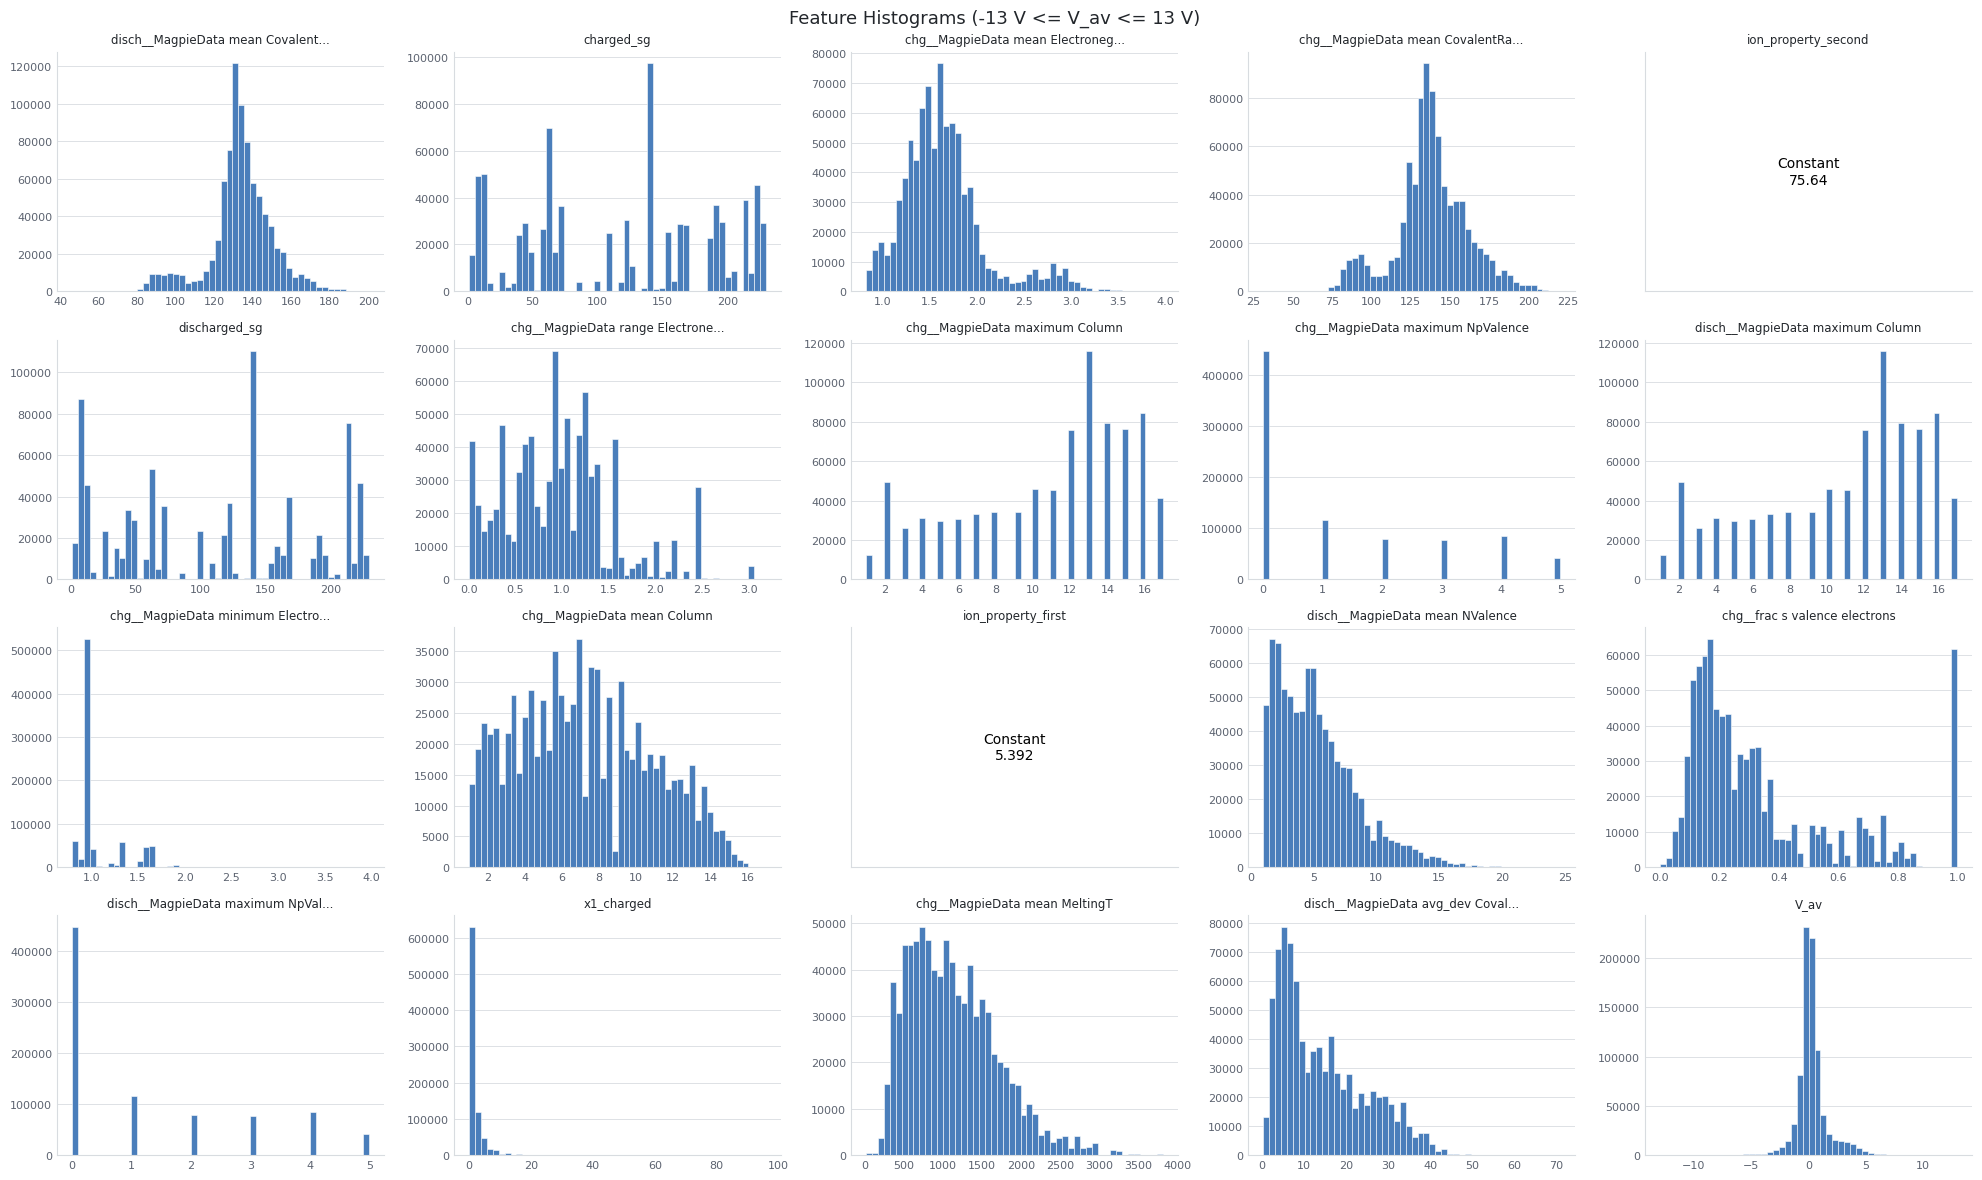

In [13]:
feature_panels(df_vav, draw_histogram, f"Feature Histograms ({VAV_MIN} V <= {TARGET} <= {VAV_MAX} V)")

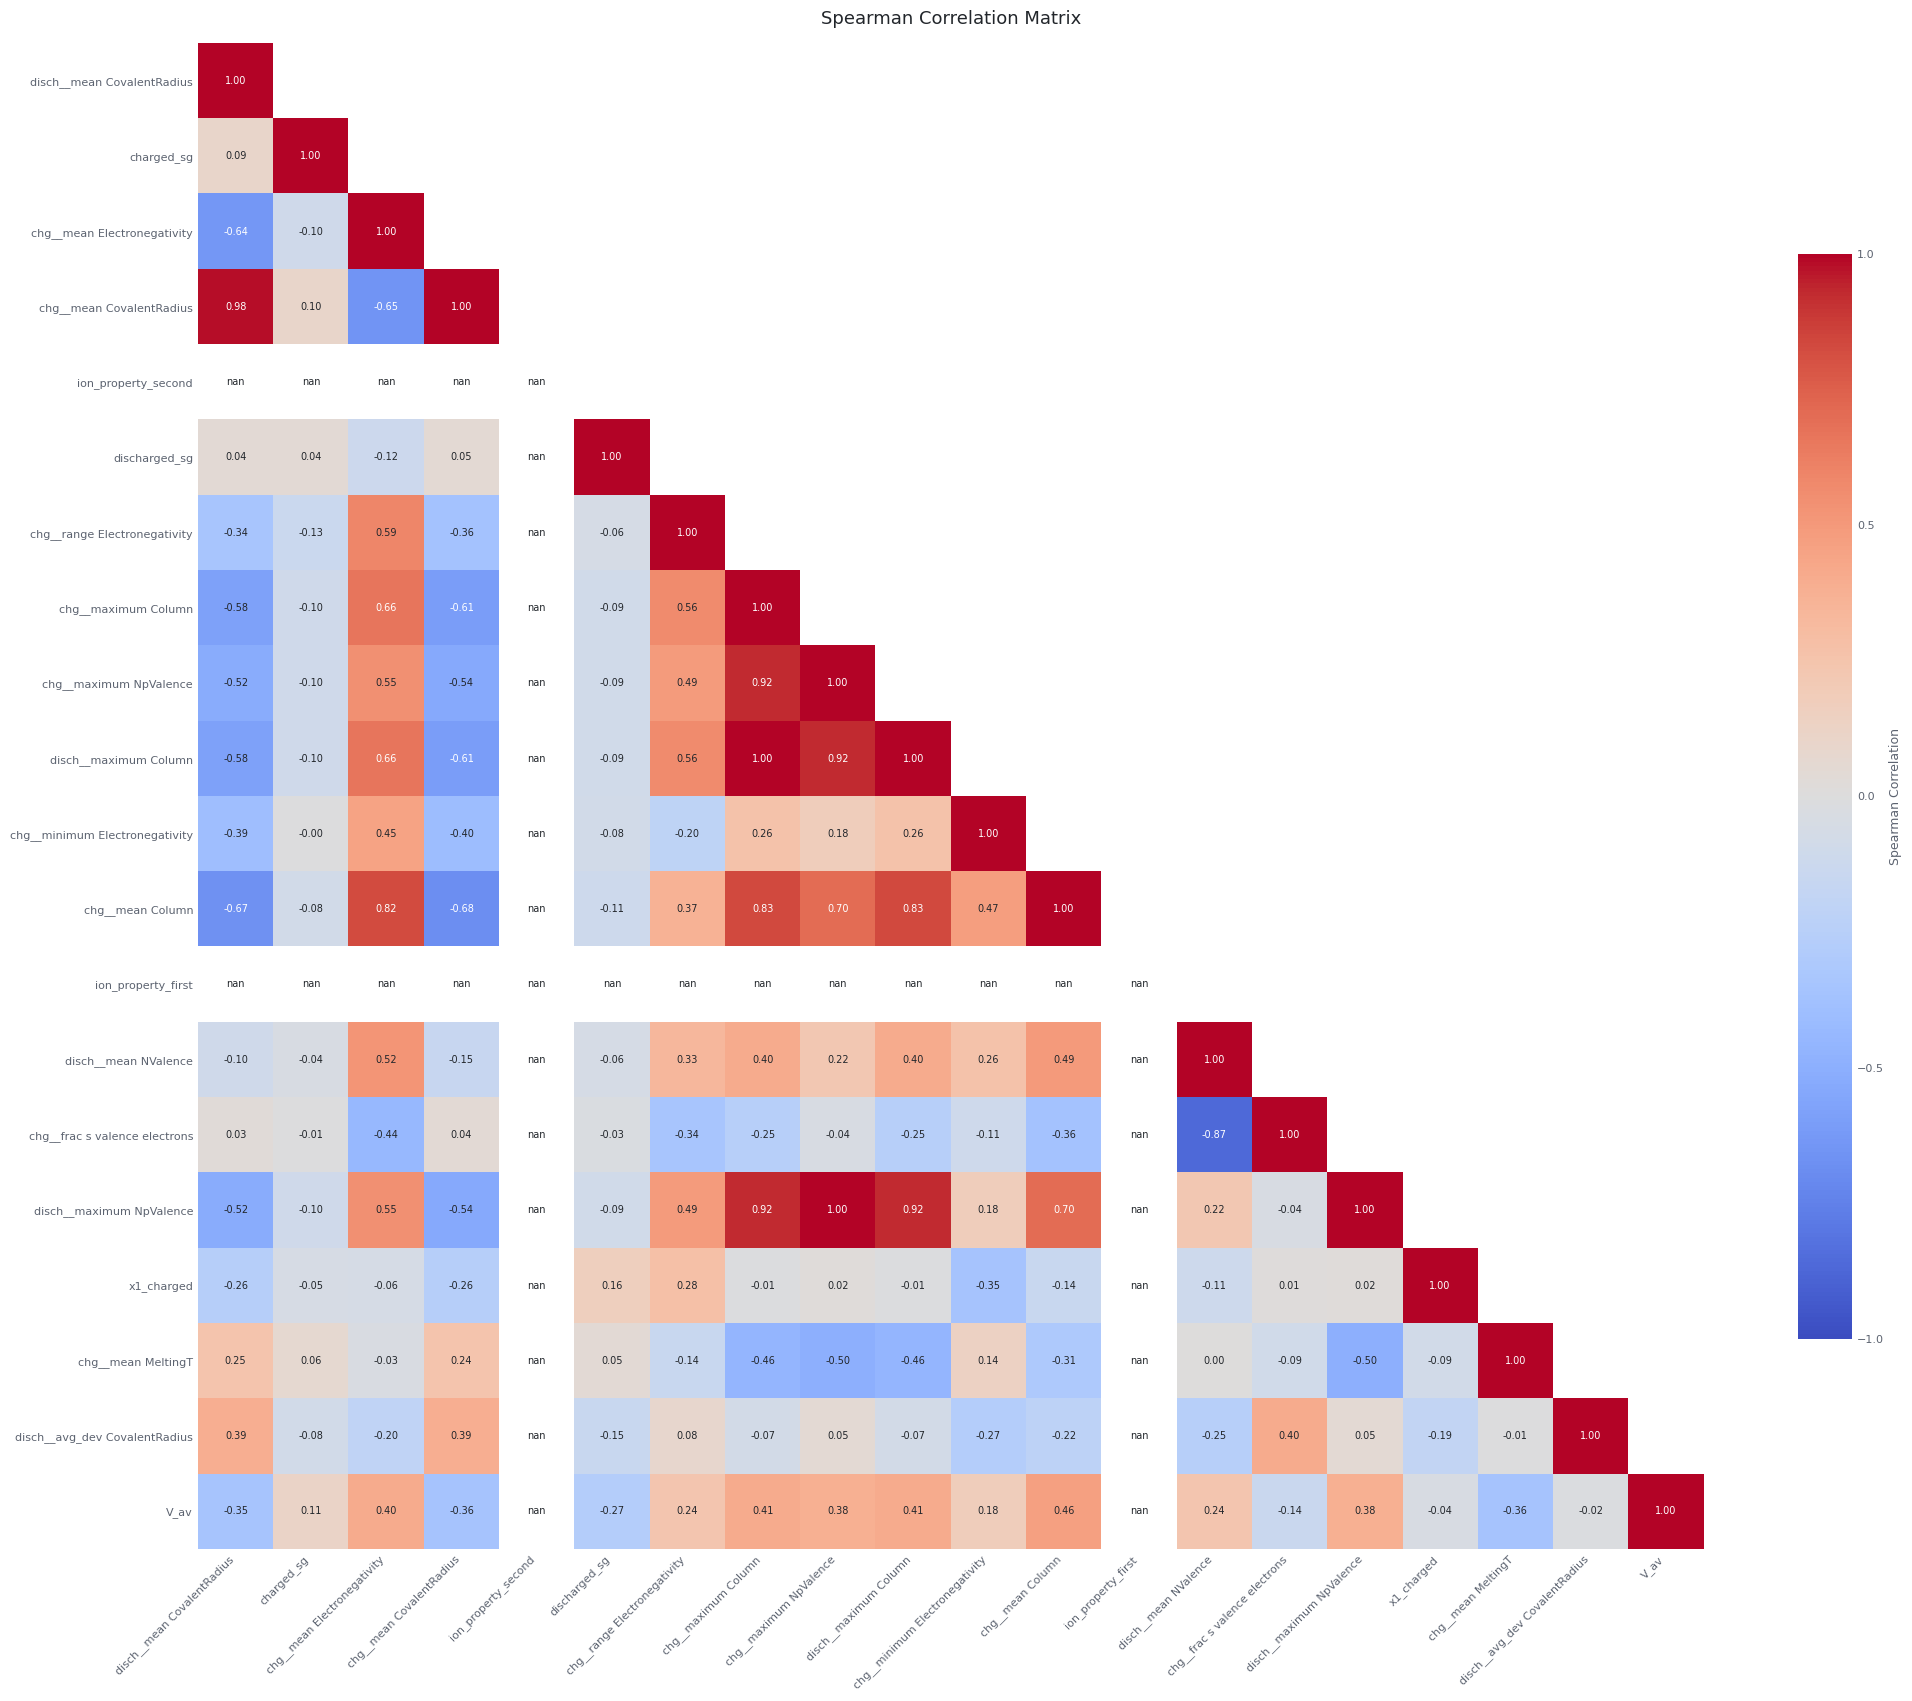

Correlation with 'V_av' (strongest first):
  +0.465  chg__MagpieData mean Column
  +0.405  chg__MagpieData maximum Column
  +0.405  disch__MagpieData maximum Column
  +0.401  chg__MagpieData mean Electronegativity
  +0.381  disch__MagpieData maximum NpValence
  +0.381  chg__MagpieData maximum NpValence
  -0.358  chg__MagpieData mean MeltingT
  -0.356  chg__MagpieData mean CovalentRadius
  -0.347  disch__MagpieData mean CovalentRadius
  -0.268  discharged_sg
  +0.240  chg__MagpieData range Electronegativity
  +0.239  disch__MagpieData mean NValence
  +0.175  chg__MagpieData minimum Electronegativity
  -0.137  chg__frac s valence electrons
  +0.112  charged_sg
  -0.043  x1_charged
  -0.023  disch__MagpieData avg_dev CovalentRadius
  +nan  ion_property_second
  +nan  ion_property_first

Feature pairs with |correlation| > 0.8:
  1.000  chg__MagpieData maximum Column <-> disch__MagpieData maximum Column
  1.000  chg__MagpieData maximum NpValence <-> disch__MagpieData maximum NpValence
  0.9

(chg__MagpieData mean Column                  0.464899
 chg__MagpieData maximum Column               0.405232
 disch__MagpieData maximum Column             0.405232
 chg__MagpieData mean Electronegativity       0.400965
 disch__MagpieData maximum NpValence          0.381499
 chg__MagpieData maximum NpValence            0.381499
 chg__MagpieData mean MeltingT               -0.357588
 chg__MagpieData mean CovalentRadius         -0.355771
 disch__MagpieData mean CovalentRadius       -0.346888
 discharged_sg                               -0.268129
 chg__MagpieData range Electronegativity      0.239531
 disch__MagpieData mean NValence              0.238503
 chg__MagpieData minimum Electronegativity    0.175251
 chg__frac s valence electrons               -0.137143
 charged_sg                                   0.112313
 x1_charged                                  -0.043088
 disch__MagpieData avg_dev CovalentRadius    -0.022865
 ion_property_second                               NaN
 ion_prope

In [14]:
corr = plot_correlation(df_vav)

summarize_correlation(corr, target=TARGET, threshold=0.8)

In [15]:
# both columns hold a single value in the Li-only dataset
CONSTANT_FEATURES = ["ion_property_second", "ion_property_first"]

df_vav = df_vav.drop(columns=CONSTANT_FEATURES)
df_vav.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 844943 entries, 0 to 844942
Data columns (total 19 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   disch__MagpieData mean CovalentRadius      844943 non-null  float64
 1   charged_sg                                 844943 non-null  float64
 2   chg__MagpieData mean Electronegativity     844943 non-null  float64
 3   chg__MagpieData mean CovalentRadius        844943 non-null  float64
 4   discharged_sg                              844943 non-null  int64  
 5   chg__MagpieData range Electronegativity    844943 non-null  float64
 6   chg__MagpieData maximum Column             844943 non-null  float64
 7   chg__MagpieData maximum NpValence          844943 non-null  float64
 8   disch__MagpieData maximum Column           844943 non-null  float64
 9   chg__MagpieData minimum Electronegativity  844943 non-null  float64
 10  chg__Mag

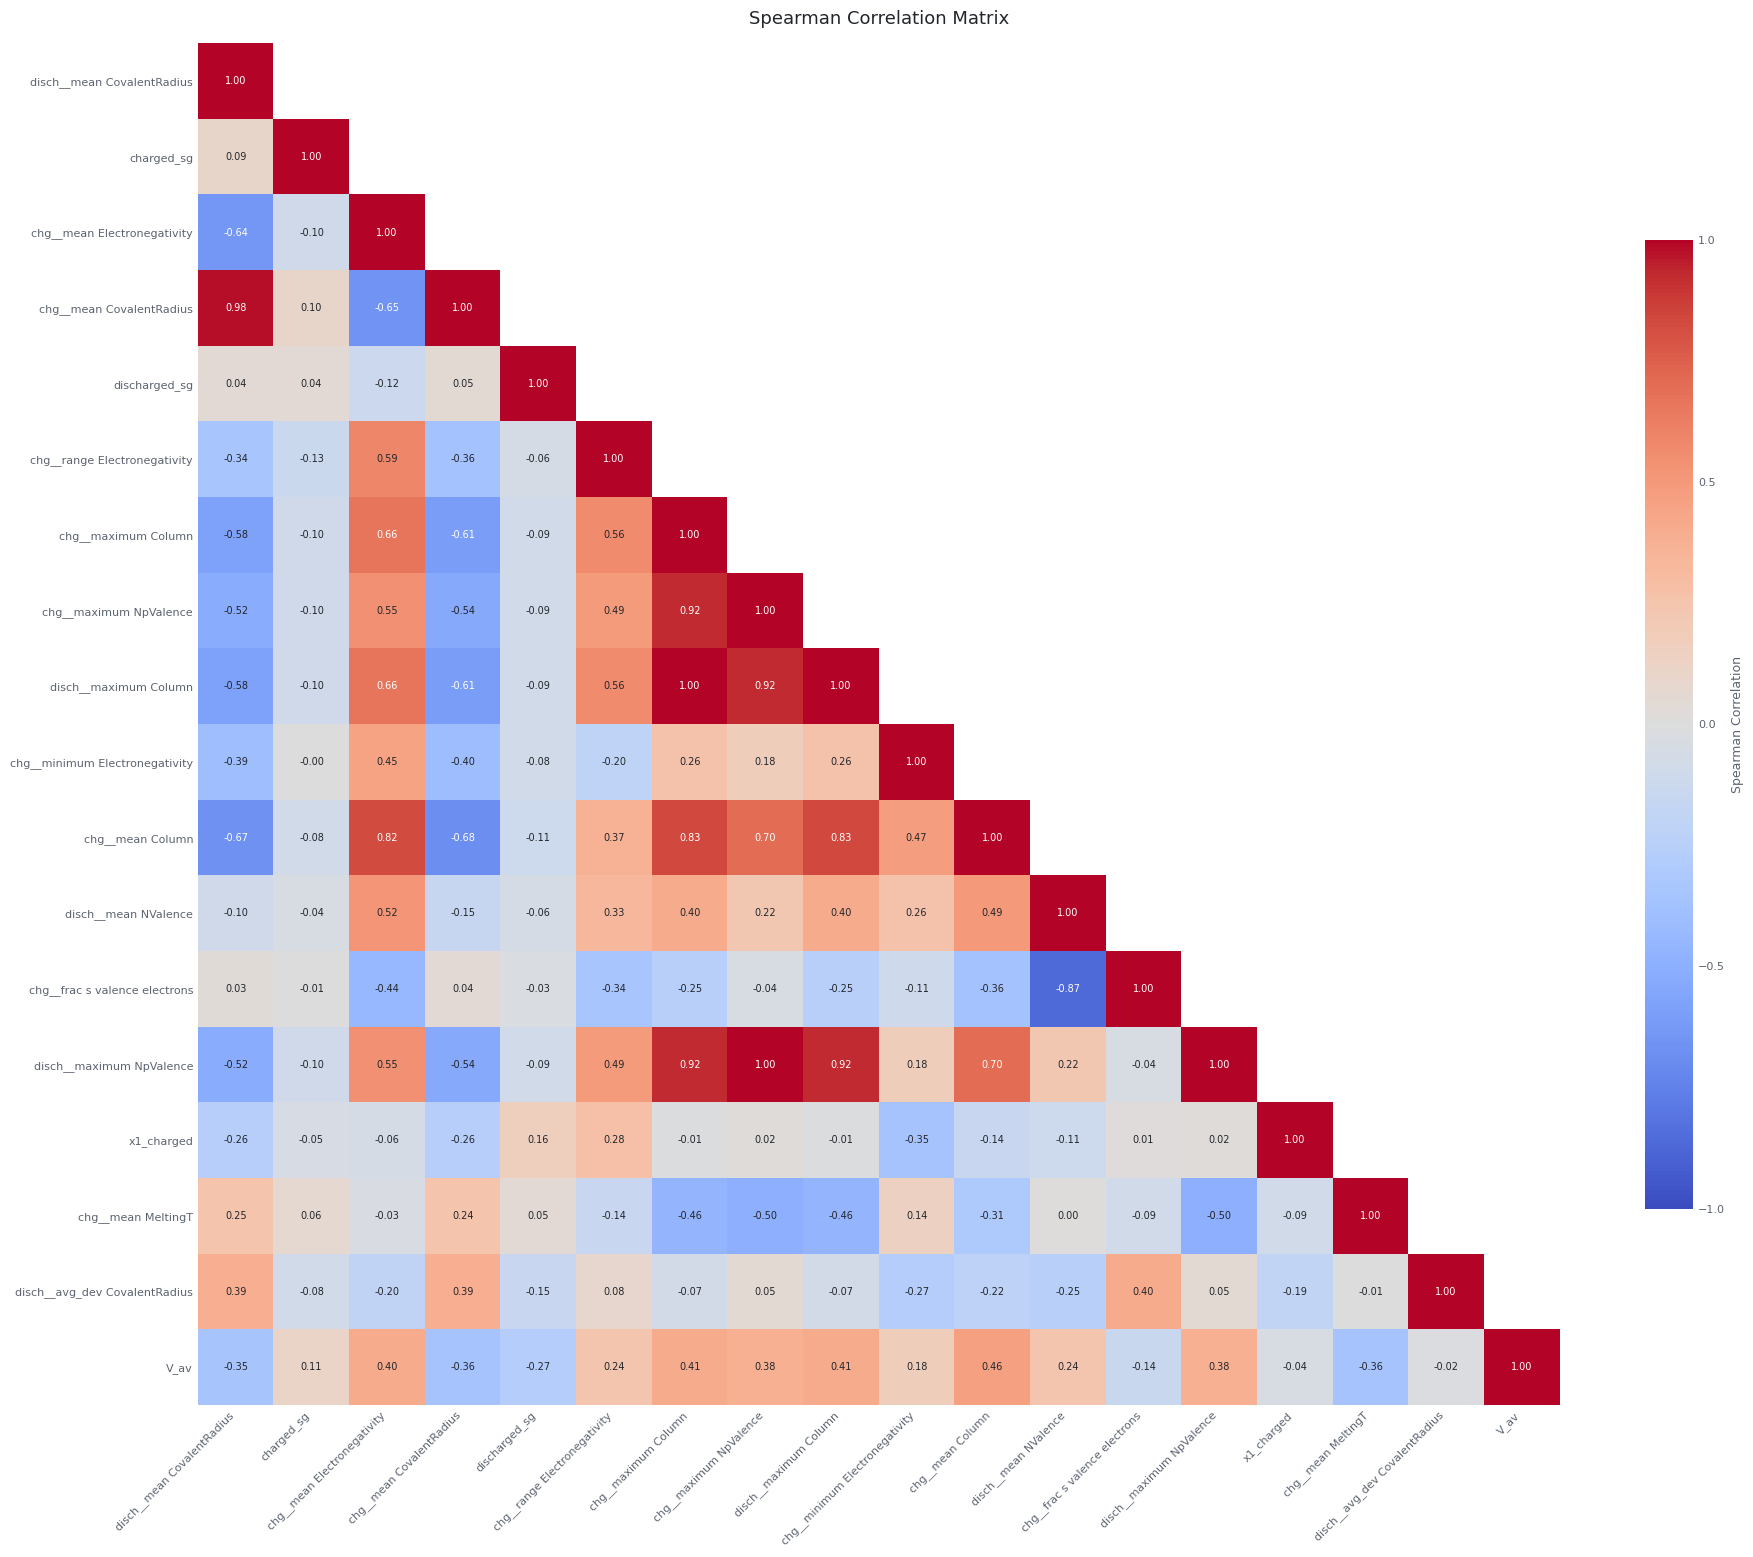

Correlation with 'V_av' (strongest first):
  +0.465  chg__MagpieData mean Column
  +0.405  chg__MagpieData maximum Column
  +0.405  disch__MagpieData maximum Column
  +0.401  chg__MagpieData mean Electronegativity
  +0.381  disch__MagpieData maximum NpValence
  +0.381  chg__MagpieData maximum NpValence
  -0.358  chg__MagpieData mean MeltingT
  -0.356  chg__MagpieData mean CovalentRadius
  -0.347  disch__MagpieData mean CovalentRadius
  -0.268  discharged_sg
  +0.240  chg__MagpieData range Electronegativity
  +0.239  disch__MagpieData mean NValence
  +0.175  chg__MagpieData minimum Electronegativity
  -0.137  chg__frac s valence electrons
  +0.112  charged_sg
  -0.043  x1_charged
  -0.023  disch__MagpieData avg_dev CovalentRadius

Feature pairs with |correlation| > 0.8:
  1.000  chg__MagpieData maximum Column <-> disch__MagpieData maximum Column
  1.000  chg__MagpieData maximum NpValence <-> disch__MagpieData maximum NpValence
  0.981  disch__MagpieData mean CovalentRadius <-> chg__Magp

(chg__MagpieData mean Column                  0.464899
 chg__MagpieData maximum Column               0.405232
 disch__MagpieData maximum Column             0.405232
 chg__MagpieData mean Electronegativity       0.400965
 disch__MagpieData maximum NpValence          0.381499
 chg__MagpieData maximum NpValence            0.381499
 chg__MagpieData mean MeltingT               -0.357588
 chg__MagpieData mean CovalentRadius         -0.355771
 disch__MagpieData mean CovalentRadius       -0.346888
 discharged_sg                               -0.268129
 chg__MagpieData range Electronegativity      0.239531
 disch__MagpieData mean NValence              0.238503
 chg__MagpieData minimum Electronegativity    0.175251
 chg__frac s valence electrons               -0.137143
 charged_sg                                   0.112313
 x1_charged                                  -0.043088
 disch__MagpieData avg_dev CovalentRadius    -0.022865
 Name: V_av, dtype: float64,
 chg__MagpieData maximum Column     

In [16]:
corr = plot_correlation(df_vav)

summarize_correlation(corr, target=TARGET, threshold=0.8)

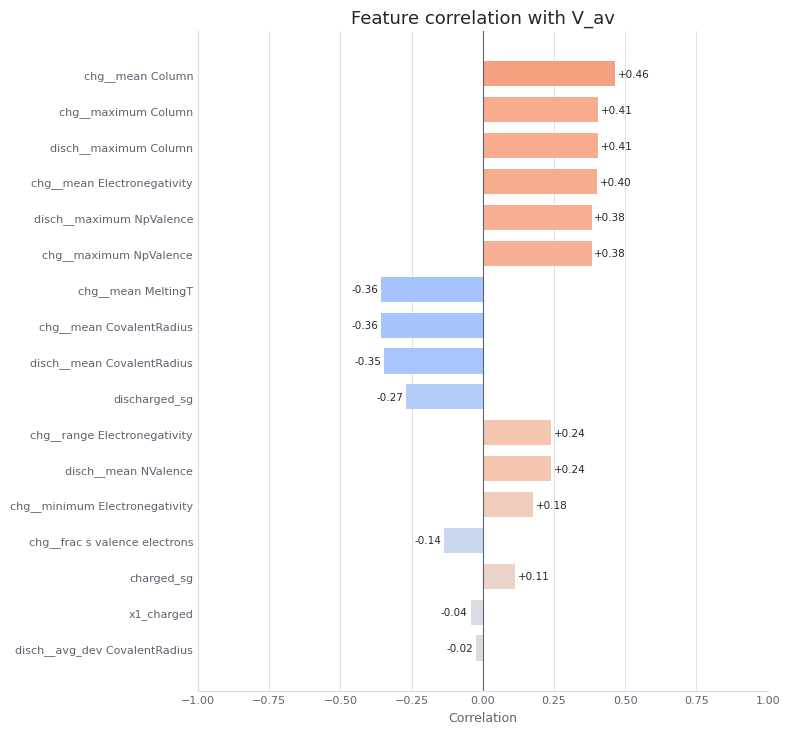

In [17]:
plot_target_correlation(corr, target=TARGET)

# Preprocessing

In [18]:
X = df_vav.drop(columns=[TARGET])
y = df_vav[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)

categorical = ", ".join(X.select_dtypes(exclude="number").columns) or "none"
print(f"features : {X.shape[1]} (categorical: {categorical})")
print(f"train    : {len(X_train):,} rows")
print(f"test     : {len(X_test):,} rows")

features : 18 (charged_cs is categorical)
train    : 675,954 rows
test     : 168,989 rows


In [19]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

In [20]:
feature_names = [
    name.split("__", 1)[-1] for name in preprocess.fit(X_train).get_feature_names_out()
]

X_train_enc = pd.DataFrame(preprocess.transform(X_train),
                           columns=feature_names, index=X_train.index)
X_test_enc = pd.DataFrame(preprocess.transform(X_test),
                          columns=feature_names, index=X_test.index)

onehot_cols = [c for c in feature_names if c.startswith(tuple(cat_cols))]
print(f"encoded shape : {X_train_enc.shape[1]} columns "
      f"({len(num_cols)} numeric + {len(onehot_cols)} one-hot)")
X_train_enc.head()

encoded shape : 24 columns (17 numeric + 7 one-hot)
one-hot from 'charged_cs' : ['charged_cs_Cubic', 'charged_cs_Hexagonal', 'charged_cs_Monoclinic', 'charged_cs_Orthorhombic', 'charged_cs_Tetragonal', 'charged_cs_Triclinic', 'charged_cs_Trigonal']


,charged_cs_Cubic,charged_cs_Hexagonal,charged_cs_Monoclinic,charged_cs_Orthorhombic,charged_cs_Tetragonal,charged_cs_Triclinic,charged_cs_Trigonal,disch__MagpieData mean CovalentRadius,charged_sg,chg__MagpieData mean Electronegativity,...,chg__MagpieData maximum NpValence,disch__MagpieData maximum Column,chg__MagpieData minimum Electronegativity,chg__MagpieData mean Column,disch__MagpieData mean NValence,chg__frac s valence electrons,disch__MagpieData maximum NpValence,x1_charged,chg__MagpieData mean MeltingT,disch__MagpieData avg_dev CovalentRadius
392783,0.0,0.0,0.0,0.0,0.0,0.0,1.0,138.750000,156.0,1.393333,...,0.0,6.0,0.98,3.666667,3.000000,0.363636,0.0,1.000000,1524.896667,10.750000
765466,0.0,0.0,0.0,0.0,1.0,0.0,0.0,151.500000,140.0,1.396667,...,2.0,14.0,0.93,5.333333,7.750000,0.133333,2.0,0.000000,447.450000,14.500000
258996,0.0,0.0,0.0,1.0,0.0,0.0,0.0,147.333333,51.0,1.475000,...,3.0,15.0,0.93,8.000000,10.333333,0.100000,3.0,0.000000,457.635000,12.888889
534980,0.0,0.0,0.0,0.0,0.0,0.0,1.0,177.750000,164.0,1.086667,...,0.0,3.0,0.82,2.333333,2.000000,0.714286,0.0,0.000000,1311.510000,24.875000
291511,0.0,0.0,0.0,0.0,0.0,0.0,1.0,106.333333,164.0,1.922000,...,2.0,14.0,0.98,8.800000,2.250000,0.571429,2.0,3.333333,2475.276000,25.277778


# Model Training

In [21]:
# LightGBM uses OpenCL ("gpu"); this build has no CUDA learner
models = {
    "XGBoost (boosting)": XGBRegressor(
        objective="reg:squarederror", tree_method="hist", device="cuda",
        random_state=RANDOM_STATE,
    ),
    "LightGBM (boosting)": LGBMRegressor(
        n_estimators=100, device="gpu", random_state=RANDOM_STATE, verbose=-1,
    ),
    "CatBoost (boosting)": CatBoostRegressor(
        iterations=100, task_type="GPU", devices="0", random_state=RANDOM_STATE,
        verbose=0,
    ),
    "RandomForest (cuML GPU)": cuRF(
        n_estimators=100, max_depth=16, n_streams=4, random_state=RANDOM_STATE,
    ),
}

for name, model in models.items():
    print(f"{name:<24} {type(model).__name__}")

XGBoost (boosting)       XGBRegressor
LightGBM (boosting)      LGBMRegressor
CatBoost (boosting)      CatBoostRegressor
RandomForest (cuML GPU)  RandomForestRegressor


In [22]:
baseline_scores, baseline_preds = evaluate_all(
    models, X_train_enc, y_train, X_test_enc, y_test, heading="Baseline (default params)",
)

/home/reesarosyid/Documents/Battery/.venv/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [19:39:04] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


done: XGBoost (boosting)       CV MAE=0.4622+/-0.0026  CV RMSE=0.8350  CV R2=0.6840  |  test MAE=0.4667  (4s of CV fits)
done: LightGBM (boosting)      CV MAE=0.5150+/-0.0025  CV RMSE=0.9298  CV R2=0.6082  |  test MAE=0.5172  (6s of CV fits)
done: CatBoost (boosting)      CV MAE=0.5173+/-0.0017  CV RMSE=0.9405  CV R2=0.5992  |  test MAE=0.5202  (7s of CV fits)


[19:39:31] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:39:41] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:39:49] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

done: RandomForest (cuML GPU)  CV MAE=0.3975+/-0.0020  CV RMSE=0.7540  CV R2=0.7424  |  test MAE=0.3974  (79s of CV fits)

=== Baseline (default params), 10-fold CV (sorted by CV MAE; lower = better) ===
                         CV RMSE  CV RMSE std  CV MAE  CV MAE std   CV R2  CV R2 std  test RMSE  test MAE  test R2   CV (s)  refit (s)
model                                                                                                                                 
RandomForest (cuML GPU)   0.7540       0.0108  0.3975      0.0020  0.7424     0.0067     0.7600    0.3974   0.7409  78.5520     8.2972
XGBoost (boosting)        0.8350       0.0128  0.4622      0.0026  0.6840     0.0079     0.8484    0.4667   0.6771   3.9498     0.2925
LightGBM (boosting)       0.9298       0.0112  0.5150      0.0025  0.6082     0.0068     0.9360    0.5172   0.6071   5.5779     0.5171
CatBoost (boosting)       0.9405       0.0119  0.5173      0.0017  0.5992     0.0066     0.9481    0.5202   0.5968   7.40

[19:40:57] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


In [23]:
# Random forest is much slower than boosting, so it is tuned on a subsample
# and re-scored on the full training set afterwards.
rf_rng = np.random.RandomState(RANDOM_STATE)
rf_idx = rf_rng.choice(len(X_train_enc), size=min(RF_TUNE_SAMPLE, len(X_train_enc)),
                       replace=False)
X_rf, y_rf = X_train_enc.iloc[rf_idx], y_train.iloc[rf_idx]

# name -> (estimator, param grid, X, y)
grids = {
    "XGBoost (boosting)": (
        XGBRegressor(objective="reg:squarederror", tree_method="hist",
                     device="cuda", random_state=RANDOM_STATE),
        {"n_estimators": [400, 800],
         "max_depth": [6, 10],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "LightGBM (boosting)": (
        LGBMRegressor(device="gpu", random_state=RANDOM_STATE, verbose=-1),
        {"n_estimators": [400, 800],
         "num_leaves": [31, 63],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "CatBoost (boosting)": (
        CatBoostRegressor(task_type="GPU", devices="0", random_state=RANDOM_STATE,
                          verbose=0),
        {"iterations": [400, 800],
         "depth": [6, 10],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "RandomForest (cuML GPU)": (
        cuRF(n_streams=4, random_state=RANDOM_STATE),
        {"n_estimators": [100, 200],
         "max_depth": [12, 16]},
        X_rf, y_rf),
}

best_params, tune_rows = {}, []
for name, (model, grid, X_tune, y_tune) in grids.items():
    search = GridSearchCV(model, grid, scoring="neg_mean_absolute_error",
                          cv=kf, n_jobs=1, refit=False, error_score="raise")
    start = time.perf_counter()
    search.fit(X_tune, y_tune)
    elapsed = time.perf_counter() - start

    best_params[name] = search.best_params_
    tune_rows.append({
        "model": name,
        "search CV MAE": -search.best_score_,
        "combos": len(search.cv_results_["params"]),
        "fits": len(search.cv_results_["params"]) * K,
        "tune (s)": elapsed,
    })
    print(f"{name:<24} search CV MAE={-search.best_score_:.4f}  ({elapsed:.0f}s)  "
          f"best={search.best_params_}")

tuning_summary = pd.DataFrame(tune_rows).set_index("model").sort_values("search CV MAE")
print(f"\nGridSearchCV summary ({K}-fold)")
print(tuning_summary.round(4).to_string())

XGBoost (boosting)       search CV MAE=0.2197  (196s)  best={'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 800}
LightGBM (boosting)      search CV MAE=0.3384  (187s)  best={'learning_rate': 0.1, 'n_estimators': 800, 'num_leaves': 63}
CatBoost (boosting)      search CV MAE=0.4044  (217s)  best={'depth': 10, 'iterations': 800, 'learning_rate': 0.1}


[19:50:58] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:50:59] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:51:00] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

RandomForest (cuML GPU)  search CV MAE=0.4472  (110s)  best={'max_depth': 16, 'n_estimators': 200}

=== GridSearchCV summary (10-fold, sorted by search CV MAE) ===
                         search CV MAE  combos  fits  tune (s)
model                                                         
XGBoost (boosting)              0.2197       8    80  195.5573
LightGBM (boosting)             0.3384       8    80  186.9833
CatBoost (boosting)             0.4044       8    80  217.2352
RandomForest (cuML GPU)         0.4472       4    40  109.5681


[19:52:46] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


# Results

In [24]:
tuned_models = {
    name: clone(grids[name][0]).set_params(**params)
    for name, params in best_params.items()
}

tuned_scores, tuned_preds = evaluate_all(
    tuned_models, X_train_enc, y_train, X_test_enc, y_test,
    heading="Tuned (GridSearchCV best params)",
)

done: XGBoost (boosting)       CV MAE=0.2197+/-0.0008  CV RMSE=0.4325  CV R2=0.9152  |  test MAE=0.2168  (51s of CV fits)
done: LightGBM (boosting)      CV MAE=0.3385+/-0.0016  CV RMSE=0.5974  CV R2=0.8382  |  test MAE=0.3388  (32s of CV fits)
done: CatBoost (boosting)      CV MAE=0.4041+/-0.0017  CV RMSE=0.7242  CV R2=0.7623  |  test MAE=0.4040  (47s of CV fits)


[19:55:31] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:55:49] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[19:56:06] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

done: RandomForest (cuML GPU)  CV MAE=0.3968+/-0.0019  CV RMSE=0.7530  CV R2=0.7430  |  test MAE=0.3975  (157s of CV fits)

=== Tuned (GridSearchCV winners), 10-fold CV (sorted by CV MAE; lower = better) ===
                         CV RMSE  CV RMSE std  CV MAE  CV MAE std   CV R2  CV R2 std  test RMSE  test MAE  test R2    CV (s)  refit (s)
model                                                                                                                                  
XGBoost (boosting)        0.4325       0.0082  0.2197      0.0008  0.9152     0.0029     0.4231    0.2168   0.9197   50.5717     5.1932
LightGBM (boosting)       0.5974       0.0106  0.3385      0.0016  0.8382     0.0051     0.5966    0.3388   0.8403   32.3853     3.5335
RandomForest (cuML GPU)   0.7530       0.0107  0.3968      0.0019  0.7430     0.0067     0.7604    0.3975   0.7406  157.0986    17.2081
CatBoost (boosting)       0.7242       0.0106  0.4041      0.0017  0.7623     0.0057     0.7225    0.4040   0.76

[19:58:27] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


=== 10-fold CV and test, before vs after tuning (gain > 0 = tuning helped) ===
                         CV MAE (base)  CV MAE (tuned)  CV RMSE (base)  CV RMSE (tuned)  CV R2 (base)  CV R2 (tuned)  test MAE (base)  test MAE (tuned)  test RMSE (base)  test RMSE (tuned)  test R2 (base)  test R2 (tuned)  CV MAE gain  test MAE gain
model                                                                                                                                                                                                                                                    
XGBoost (boosting)              0.4622          0.2197          0.8350           0.4325        0.6840         0.9152           0.4667            0.2168            0.8484             0.4231          0.6771           0.9197       0.2425         0.2499
LightGBM (boosting)             0.5150          0.3385          0.9298           0.5974        0.6082         0.8382           0.5172            0.3388            0.9360  

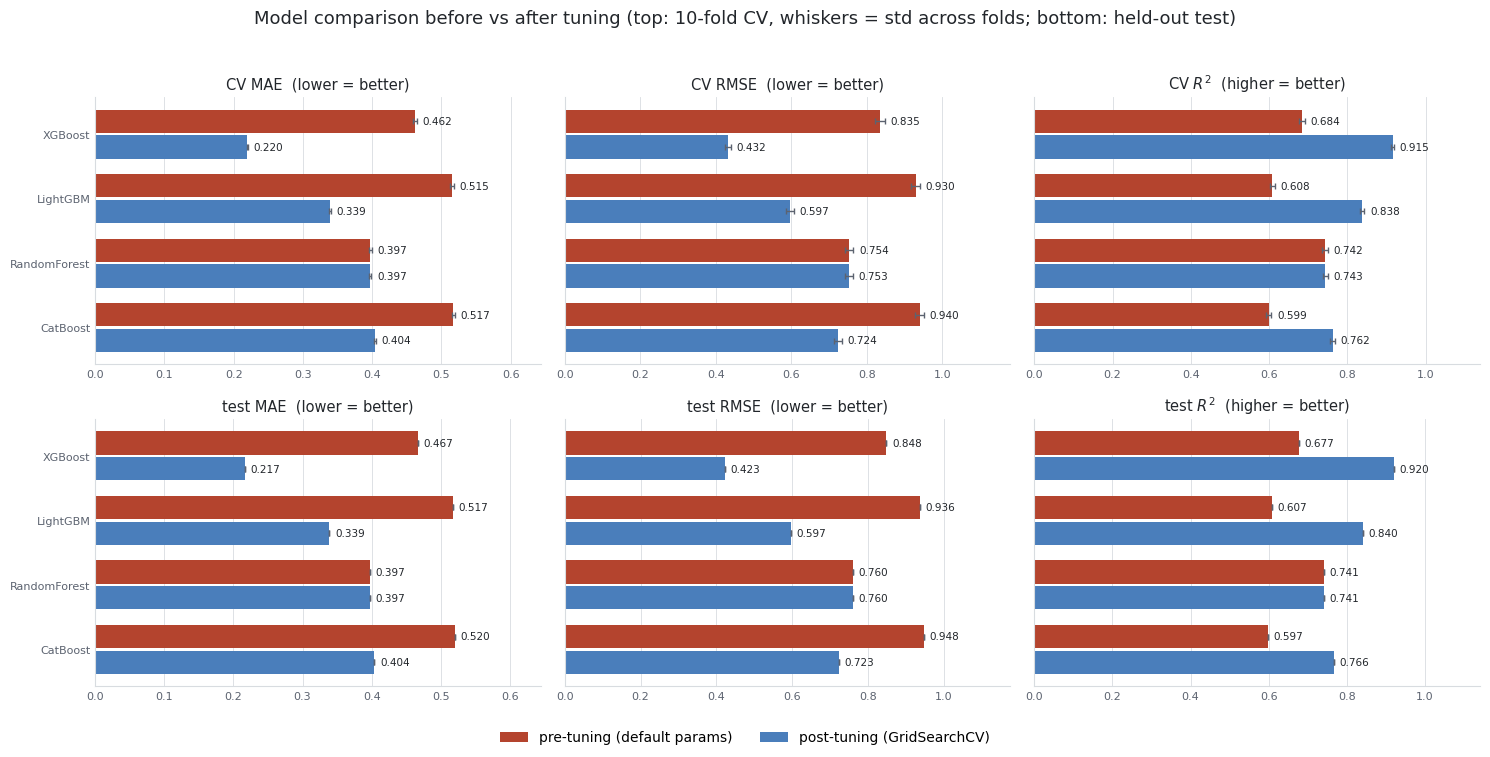

In [25]:
METRICS = ["MAE", "RMSE", "R2"]
BAR_HEIGHT = 0.36
BAR_OFFSET = BAR_HEIGHT / 2 + 0.02

compare = baseline_scores.join(tuned_scores, lsuffix=" (base)", rsuffix=" (tuned)")
compare = compare.loc[compare["CV MAE (tuned)"].sort_values().index]
compare["CV MAE gain"] = compare["CV MAE (base)"] - compare["CV MAE (tuned)"]
compare["test MAE gain"] = compare["test MAE (base)"] - compare["test MAE (tuned)"]

table_cols = [f"{source} {metric} ({stage})"
              for source in ("CV", "test") for metric in METRICS
              for stage in ("base", "tuned")] + ["CV MAE gain", "test MAE gain"]
print(f"{K}-fold CV and test, before vs after tuning (gain > 0 = improvement)")
print(compare[table_cols].round(4).to_string())

positions = np.arange(len(compare))
no_error = np.zeros(len(compare))

fig, axes = plt.subplots(2, len(METRICS), figsize=(15, 7.6), sharey=True)

for axrow, source in zip(axes, ["CV", "test"]):
    for ax, metric in zip(axrow, METRICS):
        series = [
            ("before tuning", BASE_COLOR, -BAR_OFFSET,
             compare[f"{source} {metric} (base)"],
             compare[f"CV {metric} std (base)"] if source == "CV" else no_error),
            ("after tuning", TUNED_COLOR, BAR_OFFSET,
             compare[f"{source} {metric} (tuned)"],
             compare[f"CV {metric} std (tuned)"] if source == "CV" else no_error),
        ]

        for label, color, shift, values, spread in series:
            ax.barh(positions + shift, values, BAR_HEIGHT, xerr=spread, color=color,
                    error_kw={"ecolor": SPINE, "elinewidth": 1, "capsize": 2.5},
                    label=label)
            for y_pos, value, error in zip(positions + shift, values, spread):
                ax.annotate(f"{value:.3f}", (value + error, y_pos),
                            textcoords="offset points", xytext=(4, 0),
                            va="center", fontsize=7.5, color=TEXT)

        direction = "higher is better" if metric == "R2" else "lower is better"
        pretty = "$R^2$" if metric == "R2" else metric
        ax.set_title(f"{source} {pretty} ({direction})", fontsize=10.5, color=TEXT)
        ax.set_yticks(positions)
        ax.set_yticklabels(short_names(compare.index), fontsize=9)
        ax.margins(x=0.24)
        style_axes(ax, grid_axis="x")

# sharey: one flip applies to every panel
axes[0, 0].invert_yaxis()

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=10)
fig.suptitle(f"Model comparison before and after tuning "
             f"(top: {K}-fold CV with std; bottom: test set)",
             fontsize=13, color=TEXT)
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.show()

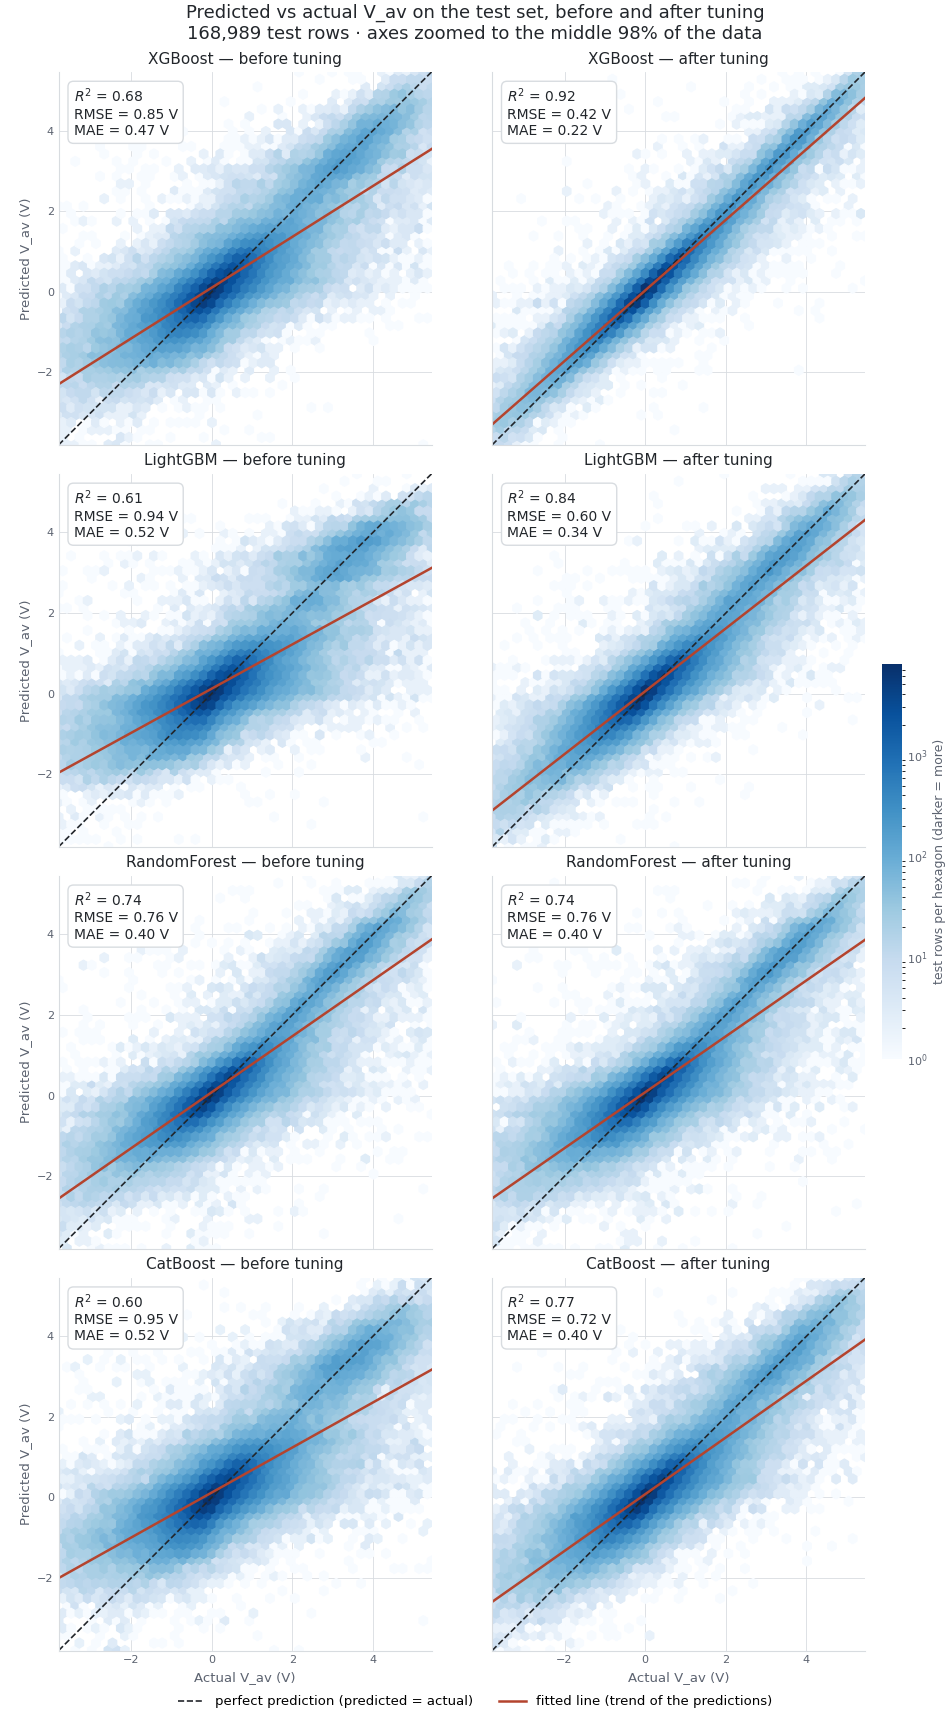

In [ ]:
if TRIM_PRED_AXES:
    low, high = trimmed_limits(y_test)
else:
    shown = np.concatenate([y_test, *baseline_preds.values(), *tuned_preds.values()])
    low, high = shown.min(), shown.max()

stages = [("before tuning", baseline_preds), ("after tuning", tuned_preds)]

fig, axes = plt.subplots(len(compare), len(stages), figsize=(9.5, 4.3 * len(compare)),
                         sharex=True, sharey=True, layout="constrained")
axes = np.atleast_2d(axes)

for row, (axrow, name) in enumerate(zip(axes, compare.index)):
    for col, (ax, (stage, preds)) in enumerate(zip(axrow, stages)):
        hexes, line_handles = plot_pred_vs_actual(ax, y_test, preds[name], low, high)

        ax.set_title(f"{short_names([name])[0]} - {stage}", fontsize=11, color=TEXT)
        if row == len(compare) - 1:
            ax.set_xlabel(f"Actual {TARGET} ({UNIT})", fontsize=9.5, color=SPINE)
        if col == 0:
            ax.set_ylabel(f"Predicted {TARGET} ({UNIT})", fontsize=9.5, color=SPINE)

bar = fig.colorbar(hexes, ax=axes, shrink=0.25, pad=0.02)
bar.set_label("test rows per hexagon", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

fig.legend(handles=list(line_handles), loc="outside lower center", ncol=2,
           frameon=False, fontsize=9.5)
fig.suptitle(f"Predicted vs actual {TARGET} on test data", fontsize=13, color=TEXT)
plt.show()

# SHAP Analysis

In [27]:
# TreeExplainer does not support the cuML forest, so the best boosting model is used
explainable = [name for name in tuned_scores.index if "cuML" not in name]
shap_name = tuned_scores.loc[explainable, "CV MAE"].idxmin()
shap_model = tuned_models[shap_name]

# avoid XGBoost device-mismatch warnings on numpy input
if isinstance(shap_model, XGBRegressor):
    shap_model.set_params(device="cpu")

rng = np.random.RandomState(RANDOM_STATE)
shap_idx = rng.choice(len(X_test_enc), size=min(SHAP_SAMPLE, len(X_test_enc)),
                      replace=False)
X_shap = X_test_enc.iloc[shap_idx]

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer(X_shap)

print(f"model       : {shap_name}  ({type(shap_model).__name__})")
print(f"SHAP values : {shap_values.values.shape[0]:,} rows x "
      f"{shap_values.values.shape[1]} features")

shap 0.52.0
explaining : XGBoost (boosting)  (XGBRegressor)
SHAP values: 3,000 rows x 24 features


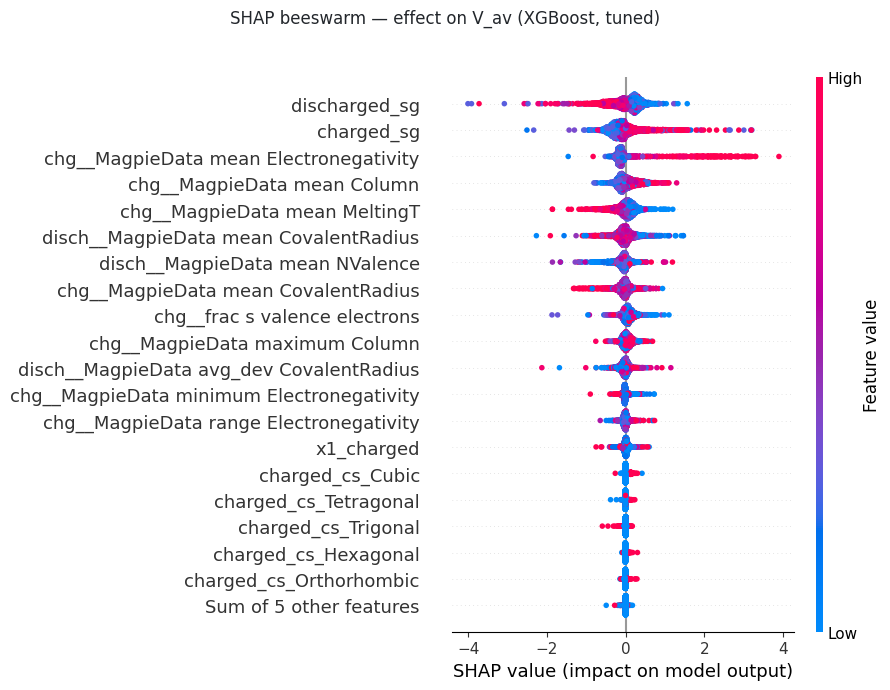

In [28]:
shap.plots.beeswarm(shap_values, max_display=20, show=False)

fig = plt.gcf()
fig.set_size_inches(9, 7)
fig.suptitle(f"SHAP beeswarm - effect on {TARGET} "
             f"({short_names([shap_name])[0]}, tuned)", fontsize=12, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

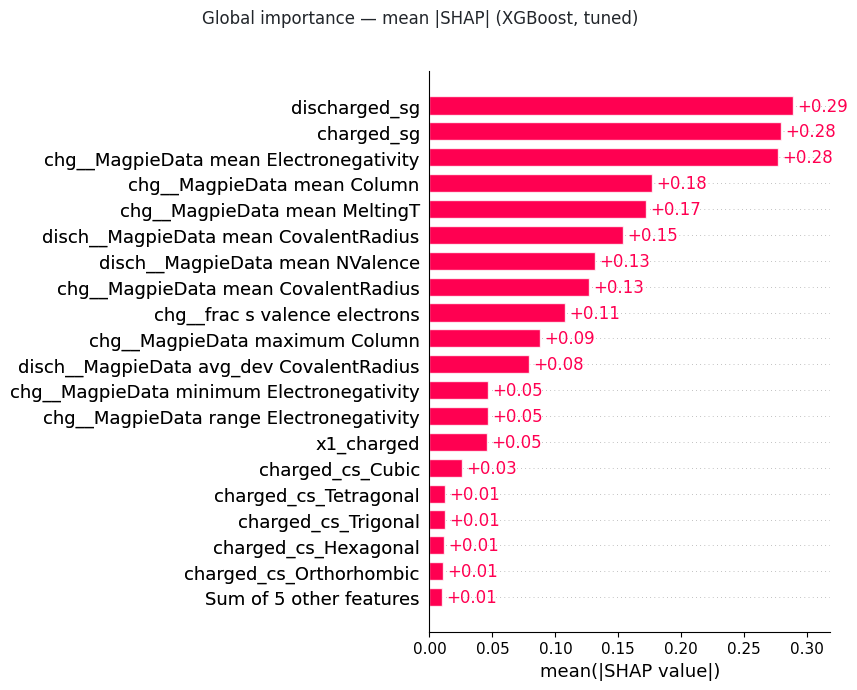

=== 15 most influential features (mean |SHAP|) ===
discharged_sg                                0.28849
charged_sg                                   0.27921
chg__MagpieData mean Electronegativity       0.27677
chg__MagpieData mean Column                  0.17634
chg__MagpieData mean MeltingT                0.17162
disch__MagpieData mean CovalentRadius        0.15401
disch__MagpieData mean NValence              0.13122
chg__MagpieData mean CovalentRadius          0.12645
chg__frac s valence electrons                0.10778
chg__MagpieData maximum Column               0.08743
disch__MagpieData avg_dev CovalentRadius     0.07906
chg__MagpieData minimum Electronegativity    0.04668
chg__MagpieData range Electronegativity      0.04653
x1_charged                                   0.04585
charged_cs_Cubic                             0.02601


In [29]:
shap.plots.bar(shap_values, max_display=20, show=False)

fig = plt.gcf()
fig.set_size_inches(8.5, 7)
fig.suptitle(f"Mean |SHAP| feature importance "
             f"({short_names([shap_name])[0]}, tuned)", fontsize=12, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

mean_abs_shap = (
    pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns,
              name="mean |SHAP|")
    .sort_values(ascending=False)
)
print("Top 15 features by mean |SHAP|")
print(mean_abs_shap.head(15).round(5).to_string())

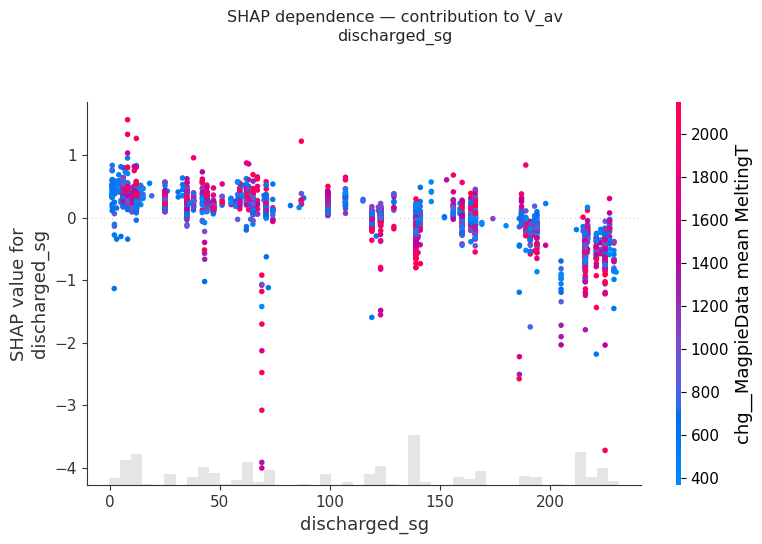

In [30]:
top_feature = mean_abs_shap.index[0]

shap.plots.scatter(shap_values[:, top_feature], color=shap_values, show=False)

fig = plt.gcf()
fig.set_size_inches(8, 5.5)
fig.suptitle(f"SHAP dependence - contribution to {TARGET}\n{top_feature}",
             fontsize=11.5, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# Partial Dependence

model    : XGBoost (boosting)
rows     : 5,000 test rows averaged over
features :
  1. discharged_sg  (mean |SHAP| = 0.2885)
  2. charged_sg  (mean |SHAP| = 0.2792)
  3. chg__MagpieData mean Electronegativity  (mean |SHAP| = 0.2768)
  4. chg__MagpieData mean Column  (mean |SHAP| = 0.1763)
  5. chg__MagpieData mean MeltingT  (mean |SHAP| = 0.1716)


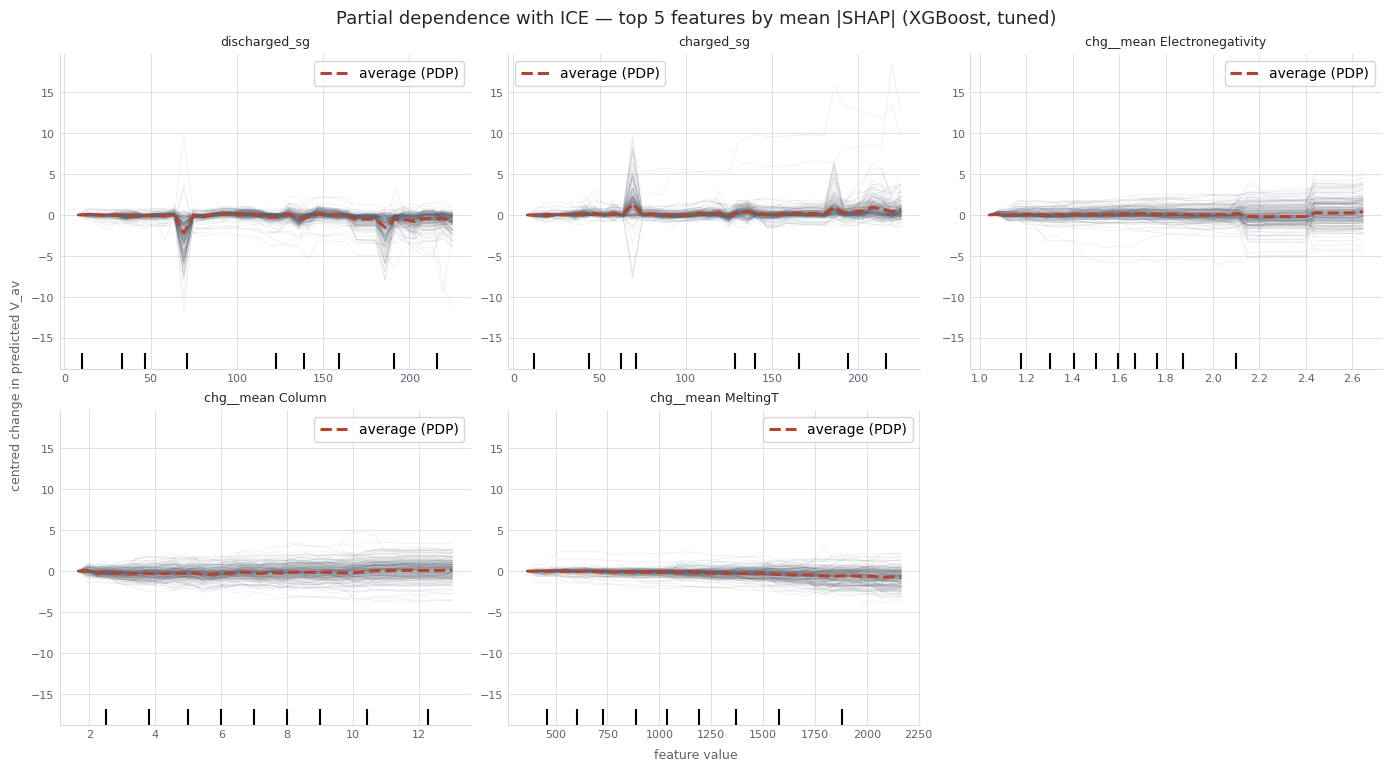

In [31]:
# Note: PDP evaluates feature combinations that may not occur in the data, and
# the Magpie features are strongly correlated.
pdp_features = [f for f in mean_abs_shap.index if f not in onehot_cols][:PDP_TOP_N]

rng_pdp = np.random.RandomState(RANDOM_STATE)
pdp_idx = rng_pdp.choice(len(X_test_enc), size=min(PDP_SAMPLE, len(X_test_enc)),
                         replace=False)
X_pdp = X_test_enc.iloc[pdp_idx]

print(f"model    : {shap_name}")
print(f"rows     : {len(X_pdp):,}")
print("features :")
for rank, name in enumerate(pdp_features, 1):
    print(f"  {rank}. {name}  (mean |SHAP| = {mean_abs_shap[name]:.4f})")

ncol = min(3, len(pdp_features))
nrow = (len(pdp_features) + ncol - 1) // ncol
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.8 * nrow),
                         layout="constrained")
axes = np.atleast_1d(axes).ravel()

PartialDependenceDisplay.from_estimator(
    shap_model, X_pdp, features=pdp_features, kind="both",
    subsample=PDP_ICE_LINES, centered=True, grid_resolution=40,
    random_state=RANDOM_STATE, ax=axes[:len(pdp_features)],
    ice_lines_kw={"color": SPINE, "alpha": 0.10, "linewidth": 0.6},
    pd_line_kw={"color": BASE_COLOR, "linewidth": 2.2, "label": "average (PDP)"},
)

for ax, name in zip(axes, pdp_features):
    ax.set_title(truncate(name.replace("MagpieData ", "")), fontsize=9, color=TEXT)
    ax.set_xlabel("")
    ax.set_ylabel("")
    style_axes(ax, grid_axis="both")

for ax in axes[len(pdp_features):]:
    ax.axis("off")

fig.supxlabel("feature value", fontsize=9, color=SPINE)
fig.supylabel(f"centered change in predicted {TARGET}", fontsize=9, color=SPINE)
fig.suptitle(f"Partial dependence and ICE - top {len(pdp_features)} features by mean "
             f"|SHAP| ({short_names([shap_name])[0]}, tuned)", fontsize=13, color=TEXT)
plt.show()

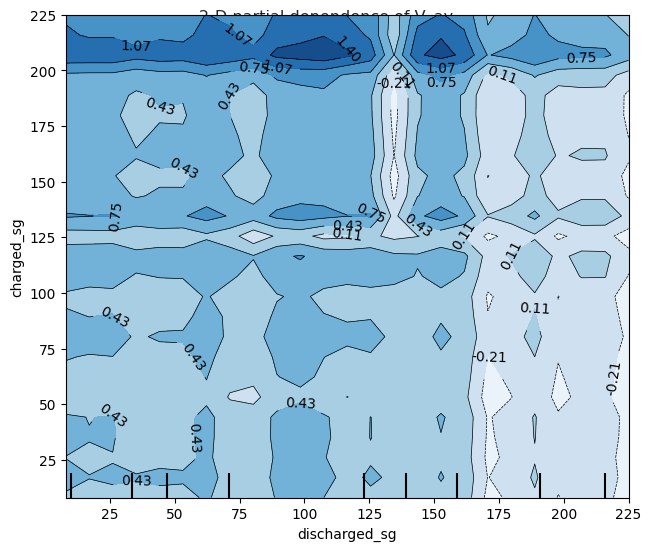

contour level = average predicted V_av when the pair is fixed and every other feature is averaged over


In [32]:
pair = pdp_features[:2]

fig, ax = plt.subplots(figsize=(6.4, 5.4), layout="constrained")

PartialDependenceDisplay.from_estimator(
    shap_model, X_pdp, features=[tuple(pair)], kind="average",
    grid_resolution=25, ax=ax,
    contour_kw={"cmap": DENSITY_CMAP, "alpha": 0.95},
)

labels = [p.replace("MagpieData ", "") for p in pair]
ax.set_xlabel(labels[0], fontsize=9, color=SPINE)
ax.set_ylabel(labels[1], fontsize=9, color=SPINE)
style_axes(ax, grid_axis="both")

ax.set_title(f"2-D partial dependence of {TARGET}\n{labels[0]} x {labels[1]}",
             fontsize=11.5, color=TEXT)
plt.show()

# Applicability Domain

model            : XGBoost (boosting)
descriptors p    : 24   train rows n : 675,954
warning leverage : h* = 3(p+1)/n = 0.00011
train leverage   : median 0.00003  max 0.00220

test rows inside the AD          : 164,048 (97.08%)
  structural outliers (h > h*)   : 2,691 (1.59%)
  response outliers (|sr| > 3)   : 2,412 (1.43%)
  both at once                   : 162


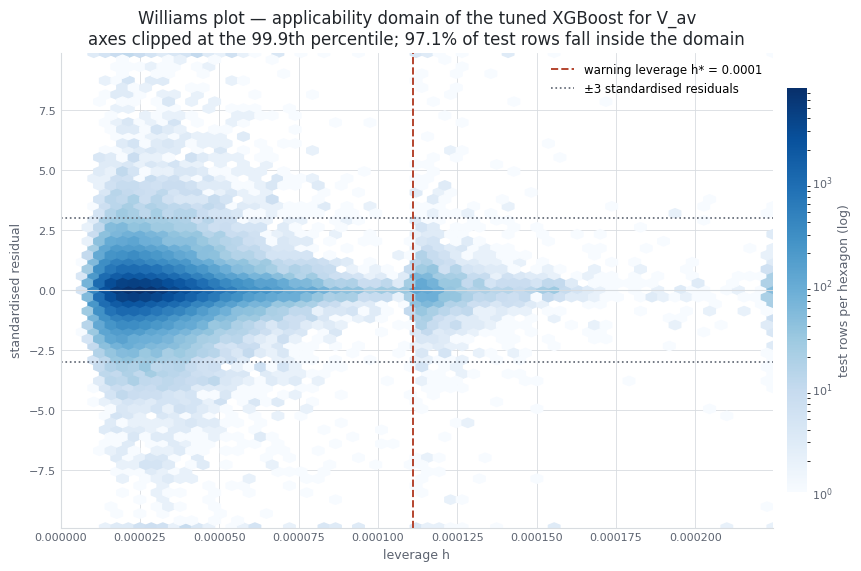

In [33]:
# Leverage h_i = z_i (Z^T Z)^-1 z_i^T with warning leverage h* = 3(p+1)/n.
# Z is standardized with training statistics; pinv handles the singular
# matrix produced by one-hot columns.
Z_train = X_train_enc.to_numpy(dtype=float)
Z_test = X_test_enc.to_numpy(dtype=float)

center = Z_train.mean(axis=0)
scale = Z_train.std(axis=0)
scale[scale == 0] = 1.0

Z_train = (Z_train - center) / scale
Z_test = (Z_test - center) / scale

gram_inv = np.linalg.pinv(Z_train.T @ Z_train)
leverage_train = np.einsum("ij,jk,ik->i", Z_train, gram_inv, Z_train)
leverage_test = np.einsum("ij,jk,ik->i", Z_test, gram_inv, Z_test)

n_train, p = Z_train.shape
h_star = 3 * (p + 1) / n_train

y_pred_ad = tuned_preds[shap_name]
residual = np.asarray(y_test) - y_pred_ad
std_residual = residual / residual.std()

outside_h = leverage_test > h_star
outside_r = np.abs(std_residual) > 3
inside = ~(outside_h | outside_r)

print(f"model            : {shap_name}")
print(f"descriptors p    : {p}   train rows n : {n_train:,}")
print(f"warning leverage : h* = {h_star:.5f}")
print(f"train leverage   : median {np.median(leverage_train):.5f}  "
      f"max {leverage_train.max():.5f}")
print()
print(f"test rows inside the AD          : {inside.sum():,} ({100 * inside.mean():.2f}%)")
print(f"  structural outliers (h > h*)   : {outside_h.sum():,} "
      f"({100 * outside_h.mean():.2f}%)")
print(f"  response outliers (|sr| > 3)   : {outside_r.sum():,} "
      f"({100 * outside_r.mean():.2f}%)")
print(f"  both                           : {(outside_h & outside_r).sum():,}")

fig, ax = plt.subplots(figsize=(8.5, 5.6), layout="constrained")

x_hi = np.quantile(leverage_test, 0.999)
y_lim = max(4.0, np.quantile(np.abs(std_residual), 0.999))
hexes = ax.hexbin(np.clip(leverage_test, 0, x_hi), np.clip(std_residual, -y_lim, y_lim),
                  gridsize=60, bins="log", cmap=DENSITY_CMAP, mincnt=1)

ax.axvline(h_star, color=BASE_COLOR, ls="--", lw=1.4,
           label=f"warning leverage h* = {h_star:.4f}")
ax.axhline(3, color=SPINE, ls=":", lw=1.2, label="±3 standardized residuals")
ax.axhline(-3, color=SPINE, ls=":", lw=1.2)
ax.axhline(0, color=GRID, lw=0.8)

ax.set_xlim(0, x_hi)
ax.set_ylim(-y_lim, y_lim)
ax.set_xlabel("leverage h", fontsize=9, color=SPINE)
ax.set_ylabel("standardized residual", fontsize=9, color=SPINE)
style_axes(ax, grid_axis="both")

bar = fig.colorbar(hexes, ax=ax, shrink=0.85, pad=0.02)
bar.set_label("test rows per hexagon (log)", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

ax.legend(loc="upper right", frameon=False, fontsize=8.5)
ax.set_title(f"Williams plot - {short_names([shap_name])[0]} (tuned), {TARGET}\n"
             f"{100 * inside.mean():.1f}% of test rows inside the domain "
             f"(axes clipped at p99.9)",
             fontsize=12, color=TEXT)
plt.show()

reference rows   : 50,000   k = 5
AD threshold     : 1.2655  (p95 of the training distances)
test rows in AD  : 160,074 (94.72%)
test rows out    : 8,915 (5.28%)

=== Test-set performance split by applicability domain (XGBoost (boosting)) ===
                 rows     MAE    RMSE      R2
inside AD      160074  0.2100  0.3968  0.9270
outside AD       8915  0.3389  0.7526  0.8395
all test rows  168989  0.2168  0.4231  0.9197


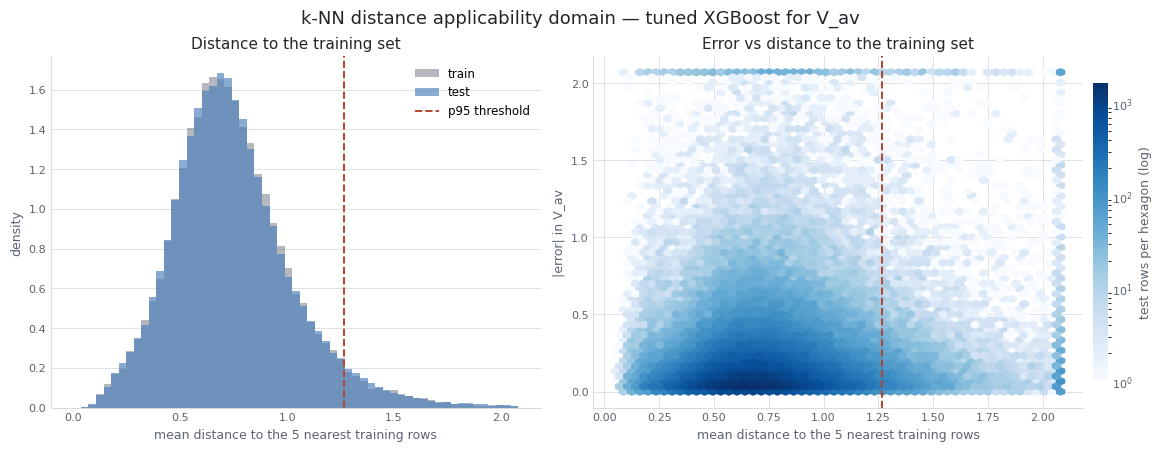

In [34]:
# Distance-based AD: a test row is out of domain when its mean distance to the
# k nearest training rows exceeds the AD_PERCENTILE of the training distances.
rng_ad = np.random.RandomState(RANDOM_STATE)
ref_idx = rng_ad.choice(n_train, size=min(AD_FIT_SAMPLE, n_train), replace=False)
Z_ref = Z_train[ref_idx]

neighbors = NearestNeighbors(n_neighbors=AD_KNN + 1).fit(Z_ref)

# skip the first neighbour of each reference row (the row itself)
dist_ref, _ = neighbors.kneighbors(Z_ref)
dist_ref = dist_ref[:, 1:].mean(axis=1)

dist_test, _ = neighbors.kneighbors(Z_test, n_neighbors=AD_KNN)
dist_test = dist_test.mean(axis=1)

ad_threshold = np.percentile(dist_ref, AD_PERCENTILE)
in_domain = dist_test <= ad_threshold

print(f"reference rows   : {len(Z_ref):,}   k = {AD_KNN}")
print(f"AD threshold     : {ad_threshold:.4f} (p{AD_PERCENTILE} of training distances)")
print(f"test rows in AD  : {in_domain.sum():,} ({100 * in_domain.mean():.2f}%)")
print(f"test rows out    : {(~in_domain).sum():,} ({100 * (~in_domain).mean():.2f}%)")

y_true_ad = np.asarray(y_test)
subsets = {
    "inside AD": in_domain,
    "outside AD": ~in_domain,
    "all test rows": np.ones_like(in_domain),
}
ad_summary = pd.DataFrame.from_dict({
    name: {
        "rows": mask.sum(),
        "MAE": mean_absolute_error(y_true_ad[mask], y_pred_ad[mask]),
        "RMSE": mean_squared_error(y_true_ad[mask], y_pred_ad[mask]) ** 0.5,
        "R2": r2_score(y_true_ad[mask], y_pred_ad[mask]),
    }
    for name, mask in subsets.items()
}, orient="index")

print(f"\nTest performance by applicability domain ({shap_name})")
print(ad_summary.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")

ax = axes[0]
bins = np.linspace(0, np.quantile(dist_test, 0.995), 60)
ax.hist(dist_ref, bins=bins, color=SPINE, alpha=0.45, density=True, label="train")
ax.hist(dist_test, bins=bins, color=ACCENT, alpha=0.65, density=True, label="test")
ax.axvline(ad_threshold, color=BASE_COLOR, ls="--", lw=1.4,
           label=f"p{AD_PERCENTILE} threshold")
ax.set_xlabel(f"mean distance to the {AD_KNN} nearest training rows",
              fontsize=9, color=SPINE)
ax.set_ylabel("density", fontsize=9, color=SPINE)
ax.set_title("Distance to the training set", fontsize=11, color=TEXT)
ax.legend(frameon=False, fontsize=8.5)
style_axes(ax)

ax = axes[1]
abs_error = np.abs(residual)
hexes = ax.hexbin(np.clip(dist_test, 0, bins[-1]),
                  np.clip(abs_error, 0, np.quantile(abs_error, 0.995)),
                  gridsize=55, bins="log", cmap=DENSITY_CMAP, mincnt=1)
ax.axvline(ad_threshold, color=BASE_COLOR, ls="--", lw=1.4)
ax.set_xlabel(f"mean distance to the {AD_KNN} nearest training rows",
              fontsize=9, color=SPINE)
ax.set_ylabel(f"|error| in {TARGET}", fontsize=9, color=SPINE)
ax.set_title("Error vs distance to the training set", fontsize=11, color=TEXT)
style_axes(ax, grid_axis="both")

bar = fig.colorbar(hexes, ax=ax, shrink=0.85, pad=0.02)
bar.set_label("test rows per hexagon (log)", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

fig.suptitle(f"k-NN applicability domain - {short_names([shap_name])[0]} (tuned), "
             f"{TARGET}", fontsize=13, color=TEXT)
plt.show()